# Семантическая сегментация на TensorFlow Lite для микроконтроллеров на Zephyr
### Подготовил: Степанюк Денис Борисович

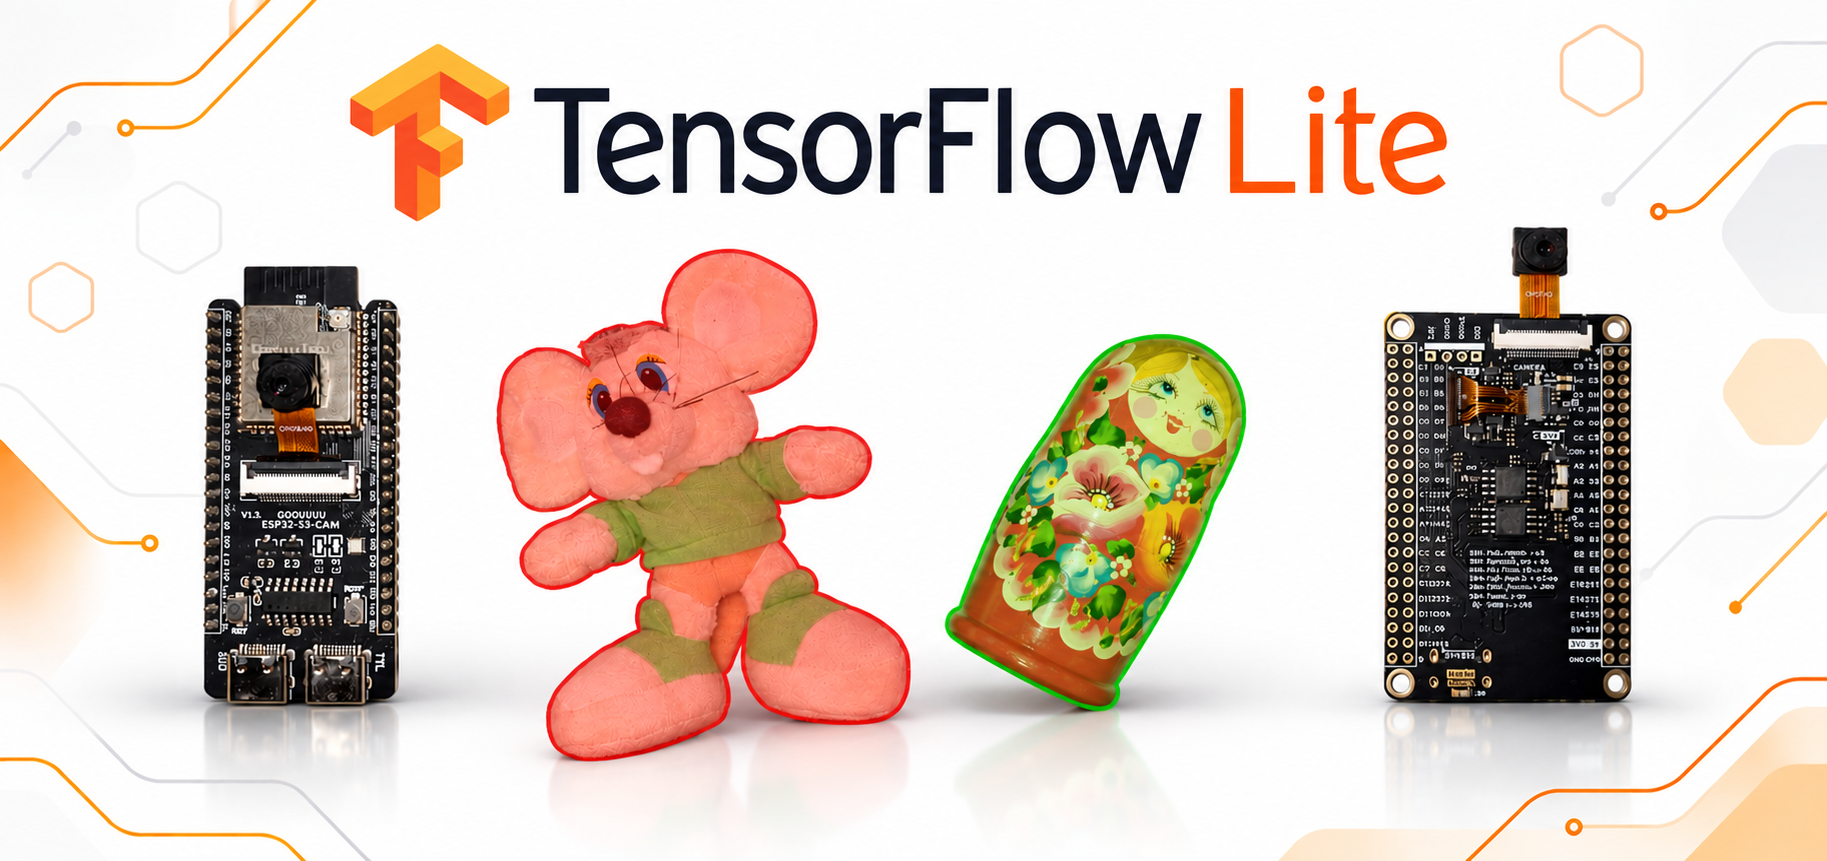

### Материалы
* U-Net: https://arxiv.org/abs/1505.04597
* Feature Pyramid Networks: https://arxiv.org/pdf/1612.03144
* labelme: https://github.com/wkentaro/labelme

# Импорт библиотек и модулей

In [1]:
import os, sys, math, json, time, random, copy, hashlib
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from tqdm.auto import tqdm
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("OpenCV:", cv2.__version__)
print("Устройства:", tf.config.list_physical_devices())

TensorFlow: 2.13.0
OpenCV: 4.10.0
Устройства: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


# Конфигурация проекта
Глобальный словарь `CFG` управляет всем конвейером: пути, классы, архитектура UNet, функция потерь, аугментация, обучение и квантование. Архитектура декодера целиком описывается блоком `CFG["unet"]` — менять код модели не нужно.

In [ ]:
# ======================================================================================
#                                      КОНФИГУРАЦИЯ
# ======================================================================================
CFG = dict(
    paths=dict(
        # Пути к папкам с обучающей, валидационной и тестовой выборками (те же кадры, что и для детекции, но с json-разметкой labelme).
        train=r"\\wsl.localhost\Ubuntu\home\stepanjuk\zephyrproject\projects\final\18_TFL_Segmentation_UNet\src\python\Datasets\Train_Dataset",
        val=r"\\wsl.localhost\Ubuntu\home\stepanjuk\zephyrproject\projects\final\18_TFL_Segmentation_UNet\src\python\Datasets\Validation_Dataset",
        test=r"\\wsl.localhost\Ubuntu\home\stepanjuk\zephyrproject\projects\final\18_TFL_Segmentation_UNet\src\python\Datasets\Test_Dataset",
        # Файл базовой нейросети (тот же backbone, что и в детекции: 13 987 параметров, стадии 16/32/64/128).
        # backbone=r"\\wsl.localhost\Ubuntu\home\stepanjuk\zephyrproject\projects\final\18_TFL_Segmentation_UNet\src\python\model_medium.h5",
        backbone=r"C:\Users\STEPANJUK\Desktop\TFL\TensorFlowLite\TFL_Segmentation\model_medium.h5",
        # Папка для хранения сгенерированных материалов.
        # out_dir="export",
        out_dir=r"C:\Users\STEPANJUK\Desktop\TFL\TensorFlowLite\TFL_Segmentation\export",
    ),
    fg_classes=["matrjona", "mouse"],        # Целевые классы без фона; индекс = номер канала на выходе модели.
    img_size=32,                             # Размер входных изображений и выходных масок (32 x 32).
    # Способ растеризации полигонов labelme в маску 32x32:
    #   "labelme" - эталонный алгоритм labelme.utils.shape_to_mask (PIL.ImageDraw.polygon),
    #   "legacy"  - ваш прежний generate_masks (cv2.fillPoly с усечением координат до int32).
    mask_mode="labelme",
    colors=[(255, 0, 0), (0, 120, 255)],     # Цвета классов для визуализации (и для наложения маски на дисплее МК).
    backbone=dict(pretrained=True,           # False -> та же архитектура, но случайные веса (абляция).
                  trainable=True),           # False -> бэкбон заморожен (обучается только декодер).
    # ---------------------------- Архитектура UNet-декодера поверх backbone ----------------------------
    unet=dict(
        bottleneck="s2b0_pw_relu6",                                  # 4x4x128: самый глубокий уровень (вход декодера).
        bottleneck_ch=64,                                            # 1x1-свёртка, сжимающая bottleneck (0 = не сжимать).
        skips=("s1b0_pw_relu6", "s0b0_pw_relu6", "stem_relu6"),      # скипы от глубоких к мелким: 8x8x64, 16x16x32, 32x32x16.
        skip_ch=(16, 16, 8),                                         # 1x1-проекция скипа перед объединением (0 = без проекции).
        dec_ch=(32, 16, 16),                                         # каналы после каждого уровня декодера: 8x8, 16x16, 32x32.
        merge="concat",                                              # "concat" (классический UNet) или "add" (как в FPN, экономнее по RAM).
        blocks=1,                                                    # число блоков (dw3x3 + pw1x1) на уровень декодера.
        out_bias=-2.0,                                               # начальный bias выходных логитов (sigmoid(-2)=0.12): объектов мало.
    ),
    # ---------------------------------------- Функция потерь ----------------------------------------
    loss=dict(w_bce=1.0, w_dice=1.0, w_focal=0.0,                    # итог = w_bce*BCE + w_dice*Dice + w_focal*Focal.
              focal_gamma=2.0, focal_alpha=0.25, dice_smooth=1.0),
    # ---------------------------------------- Метрики / порог ----------------------------------------
    post=dict(thr=0.5,                                               # порог вероятности на время обучения (потом подбирается по val для каждого класса).
              min_fp_px=1),                                          # кадр фона считается ложным, если предсказано >= min_fp_px пикселей.
    # ---------------------------------------- Аугментация ----------------------------------------
    aug=dict(p_flip=0.5,                 # Зеркальное отражение.
             p_affine=0.8,               # Аффинные преобразования (масштаб, сдвиг, пропорции).
             scale=(0.75, 1.25),         # Диапазон масштаба.
             aspect=(0.87, 1.15),        # Диапазон изменения пропорций.
             shift=0.15,                 # Максимальный сдвиг (доля кадра).
             min_vis=0.45,               # Аффинное преобразование отклоняется, если остаётся < min_vis ожидаемой площади объектов.
             p_photo=0.9,                # Яркость/контраст/насыщенность/баланс белого/гамма.
             p_noise=0.4,                # Гауссов шум.
             p_blur=0.15,                # Лёгкое размытие.
             p_erase=0.25,               # Стирание прямоугольника (в маске он тоже становится фоном).
             p_mosaic=0.10),             # Мозаика 2x2 из четырёх кадров.
    # ---------------------------------------- Обучение ----------------------------------------
    train=dict(seed=42, batch_size=32, epochs=150, patience=30,
               lr_head=2e-3, lr_backbone=6e-4, weight_decay=1e-4, warmup_epochs=3,
               clip_norm=5.0, ema_decay=0.995, min_lr_ratio=0.02),
    # Количество кадров для калибровки при квантовании в INT8.
    quant=dict(calib_samples=300),
)
OUT_DIR = Path(CFG["paths"]["out_dir"]); OUT_DIR.mkdir(parents=True, exist_ok=True)
FG = CFG["fg_classes"]; NC = len(FG); IMG = CFG["img_size"]; COLORS = CFG["colors"]
IMG_EXTS = (".jpg", ".jpeg", ".png", ".bmp")

# Функция фиксации генератора случайных чисел для воспроизводимости результатов.
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    try:
        tf.keras.utils.set_random_seed(seed)
    except Exception:
        pass

# Шаг 1. Загрузка датасета
Функция рекурсивно обходит папку, находит изображения и для каждого читает одноимённый `.json` (labelme). Из полигонов строится маска `uint8 [32, 32, NumClasses]` со значениями **0/1**. Один класс — один канал.

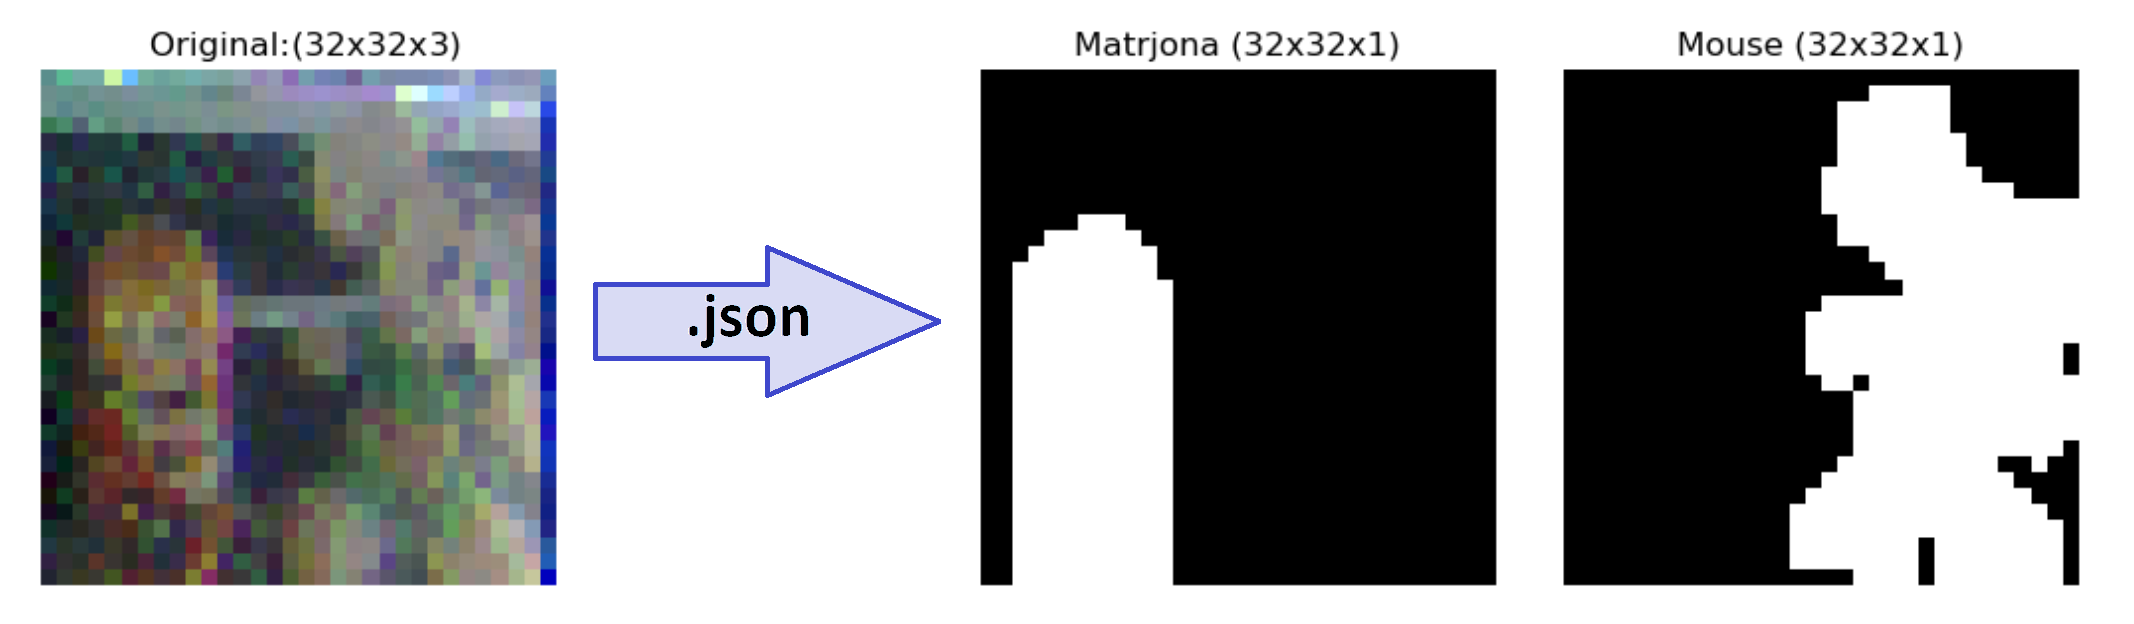

In [3]:
# Вершины фигуры labelme -> список (x, y) полигона; None, если тип фигуры не поддерживается.
def shape_points(shape):
    st = shape.get("shape_type", "polygon") or "polygon"; pts = shape.get("points") or []
    if st == "polygon" and len(pts) >= 3:
        return [(float(p[0]), float(p[1])) for p in pts]
    if st == "rectangle" and len(pts) == 2:
        (x1, y1), (x2, y2) = pts
        return [(x1, y1), (x2, y1), (x2, y2), (x1, y2)]
    if st == "circle" and len(pts) == 2:
        (cx, cy), (px, py) = pts; r = math.hypot(px - cx, py - cy)
        return [(cx + r * math.cos(a), cy + r * math.sin(a)) for a in np.linspace(0.0, 2 * math.pi, 36, endpoint=False)]
    return None

# Растеризация одного полигона в бинарную маску [S, S] (0/1).
def raster_polygon(poly, size, mode):
    if mode == "legacy":                      # прежний алгоритм: усечение координат до целых
        m = np.zeros((size, size), np.uint8); cv2.fillPoly(m, [np.array(poly, np.int32)], 1); return m
    im = Image.new("L", (size, size), 0)      # эталон labelme: labelme.utils.shape_to_mask
    ImageDraw.Draw(im).polygon([tuple(p) for p in poly], outline=1, fill=1)
    return np.asarray(im, np.uint8)

# json labelme -> маски uint8 [S, S, NumClasses] (0/1) и словарь со статистикой пропусков.
def json_to_masks(json_path, name2idx, size=IMG, mode="labelme"):
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)
    W = int(data.get("imageWidth") or size); H = int(data.get("imageHeight") or size)
    sx, sy = size / float(W), size / float(H)             # если разметка делалась на кадре другого размера
    masks = np.zeros((size, size, len(name2idx)), np.uint8)
    info = dict(n_shapes=0, unknown=0, unsupported=0, resized=int((W, H) != (size, size)))
    for sh in data.get("shapes", []):
        nm = str(sh.get("label", "")).strip().lower()
        if nm not in name2idx:
            info["unknown"] += 1; continue
        poly = shape_points(sh)
        if poly is None:
            info["unsupported"] += 1; continue
        if info["resized"]:
            poly = [(x * sx, y * sy) for x, y in poly]
        c = name2idx[nm]; masks[:, :, c] = np.maximum(masks[:, :, c], raster_polygon(poly, size, mode)); info["n_shapes"] += 1
    return masks, info

# Загрузка датасета: рекурсивно обходит папку (root), находит изображения и сопоставляет им json-разметку.
def load_split(root, fg_classes=FG, size=IMG, mode=None, verbose=True):
    """Возвращает dict: images uint8 [N,S,S,3], masks uint8 [N,S,S,NC] (0/1), paths."""
    mode = mode or CFG["mask_mode"]
    root = Path(root); name2idx = {c.lower(): i for i, c in enumerate(fg_classes)}
    images, masks, paths = [], [], []
    skipped = dict(no_json=0, unknown_cls=0, bad_size=0, unsupported_shapes=0); n_bg = 0
    if not root.exists():
        print("[!] Путь не найден:", root)
    for dp, _, files in sorted(os.walk(root)):
        for fn in sorted(files):
            stem, ext = os.path.splitext(fn)
            if ext.lower() not in IMG_EXTS: continue
            ip = Path(dp) / fn; jp = Path(dp) / (stem + ".json")
            is_bg_dir = "background" in [p.lower() for p in Path(dp).relative_to(root).parts]
            img = Image.open(ip).convert("RGB")
            if img.size != (size, size):
                skipped["bad_size"] += 1
                if skipped["bad_size"] == 1:
                    print("[!] %s имеет размер %s, ожидается %s — файл пропущен" % (ip, img.size, (size, size)))
                continue
            if jp.exists():
                m, info = json_to_masks(jp, name2idx, size, mode)
                skipped["unsupported_shapes"] += info["unsupported"]
                if info["unknown"] and info["n_shapes"] == 0:
                    skipped["unknown_cls"] += 1; continue
            elif is_bg_dir:
                m = np.zeros((size, size, len(fg_classes)), np.uint8)
            else:
                skipped["no_json"] += 1; continue
            if m.sum() == 0: n_bg += 1
            images.append(np.asarray(img, np.uint8)); masks.append(m); paths.append(str(ip))
    data = dict(images=np.stack(images) if images else np.zeros((0, size, size, 3), np.uint8),
                masks=np.stack(masks) if masks else np.zeros((0, size, size, len(fg_classes)), np.uint8), paths=paths)
    if verbose:
        pres = data["masks"].reshape(len(images), -1, len(fg_classes)).max(1).sum(0) if images else np.zeros(len(fg_classes), int)
        print("%20s: кадров %d (фон %d) | кадров с классом %s | пропущено %s" % (root.name, len(images), n_bg, dict(zip(fg_classes, pres.tolist())), skipped))
    return data

In [4]:
train_data = load_split(CFG["paths"]["train"])
val_data   = load_split(CFG["paths"]["val"])
test_data  = load_split(CFG["paths"]["test"])
assert len(train_data["images"]) > 0, "Проверьте пути в CFG['paths']"

       Train_Dataset: кадров 2226 (фон 645) | кадров с классом {'matrjona': 982, 'mouse': 971} | пропущено {'no_json': 0, 'unknown_cls': 0, 'bad_size': 0, 'unsupported_shapes': 0}
  Validation_Dataset: кадров 327 (фон 100) | кадров с классом {'matrjona': 129, 'mouse': 128} | пропущено {'no_json': 0, 'unknown_cls': 0, 'bad_size': 0, 'unsupported_shapes': 0}
        Test_Dataset: кадров 325 (фон 100) | кадров с классом {'matrjona': 127, 'mouse': 128} | пропущено {'no_json': 0, 'unknown_cls': 0, 'bad_size': 0, 'unsupported_shapes': 0}


### Статистика данных и визуальная проверка масок
Для сегментации важны доли пикселей классов (дисбаланс «объект/фон»), площадь объектов и то, как часто классы перекрываются. Ниже — таблица по сплитам и сетка примеров по категориям (фон / только matrjona / только mouse / оба) с наложением масок.

train: кадров 2226 | фон 645 | кадров с перекрытием классов 158 (пикселей в сумме 1061)
   matrjona  кадров  982 | доля пикселей по всему сплиту 9.20 % | площадь объекта px: медиана 188, мин 58, макс 790
   mouse     кадров  971 | доля пикселей по всему сплиту 13.98 % | площадь объекта px: медиана 302, мин 82, макс 897
val: кадров 327 | фон 100 | кадров с перекрытием классов 14 (пикселей в сумме 54)
   matrjona  кадров  129 | доля пикселей по всему сплиту 8.35 % | площадь объекта px: медиана 212, мин 58, макс 564
   mouse     кадров  128 | доля пикселей по всему сплиту 13.16 % | площадь объекта px: медиана 324, мин 116, макс 876
test: кадров 325 | фон 100 | кадров с перекрытием классов 10 (пикселей в сумме 70)
   matrjona  кадров  127 | доля пикселей по всему сплиту 9.12 % | площадь объекта px: медиана 203, мин 79, макс 851
   mouse     кадров  128 | доля пикселей по всему сплиту 12.85 % | площадь объекта px: медиана 322, мин 70, макс 786


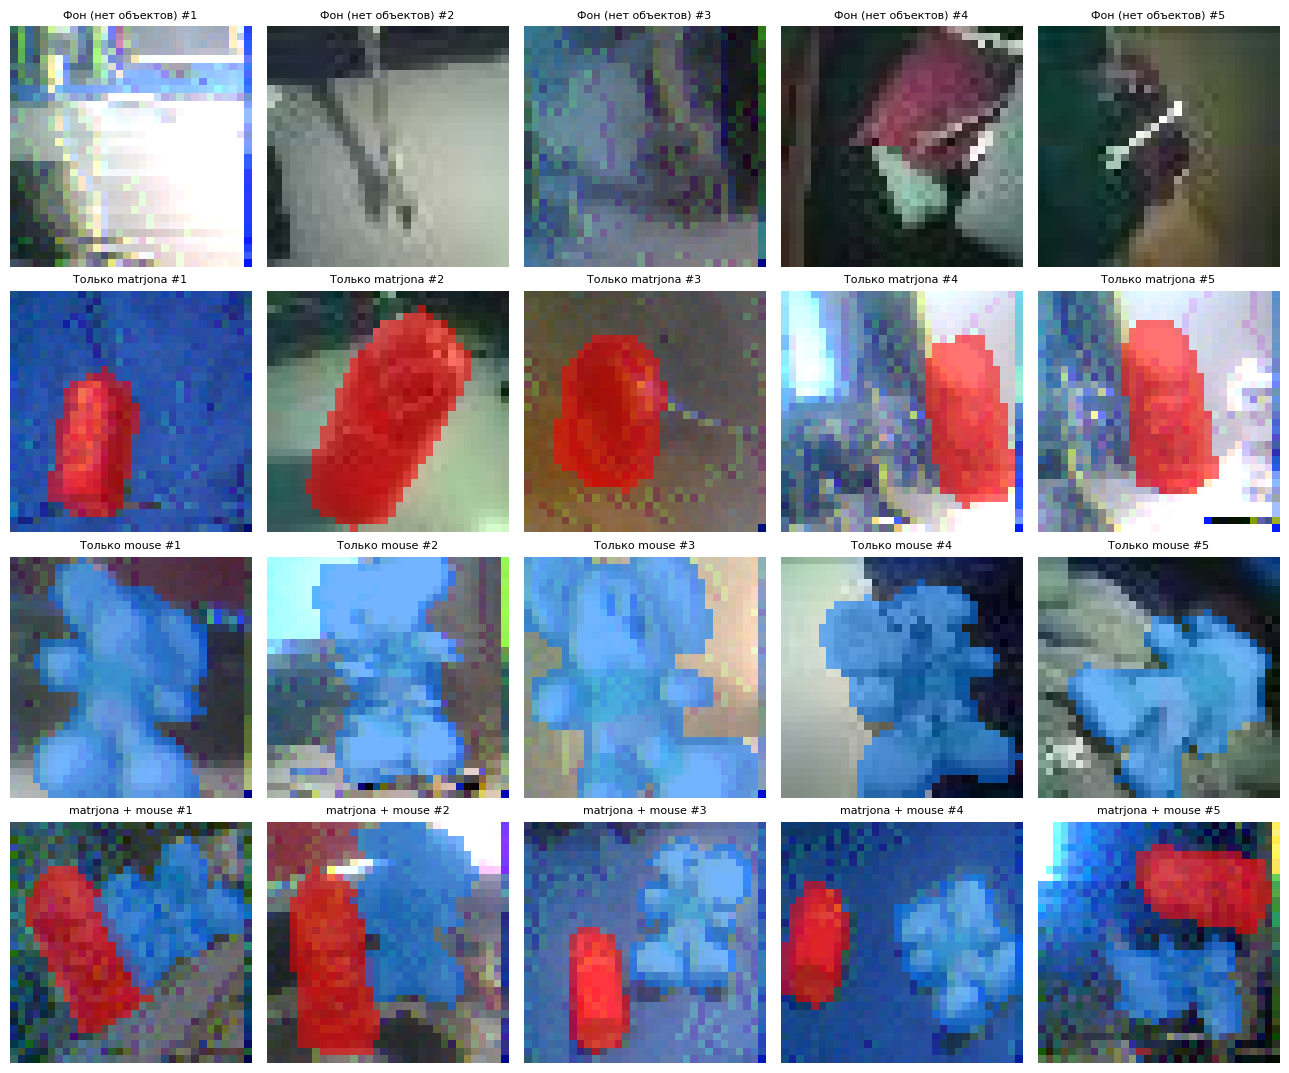

In [5]:
# Наложение масок классов на изображение (цвет класса задаётся в CFG["colors"]).
def overlay_masks(img_u8, masks, alpha=0.55, colors=COLORS):
    out = img_u8.astype(np.float32)
    for c in range(masks.shape[-1]):
        m = (masks[..., c] > 0.5)[..., None]; col = np.array(colors[c], np.float32)[None, None, :]
        out = np.where(m, (1.0 - alpha) * out + alpha * col, out)
    return np.clip(out, 0, 255).astype(np.uint8)

# Сводка по сплиту: доли пикселей классов, площади объектов, перекрытие классов.
def describe_split(data, name):
    m = data["masks"] > 0; n = len(m)
    if n == 0: print(name, ": пусто"); return
    px = m.sum((1, 2)); present = px > 0                                   # [N, C]
    overlap = (m.sum(-1) >= 2).sum((1, 2))                                 # пикселей с двумя классами сразу
    print("%s: кадров %d | фон %d | кадров с перекрытием классов %d (пикселей в сумме %d)" % (
        name, n, int((~present.any(1)).sum()), int((overlap > 0).sum()), int(overlap.sum())))
    for c, nm in enumerate(FG):
        a = px[present[:, c], c]
        print("   %-9s кадров %4d | доля пикселей по всему сплиту %.2f %% | площадь объекта px: медиана %s, мин %s, макс %s" % (
            nm, int(present[:, c].sum()), 100.0 * m[..., c].mean(), int(np.median(a)) if len(a) else "-", int(a.min()) if len(a) else "-", int(a.max()) if len(a) else "-"))

# Демонстрационная визуализация: 4 категории x 5 примеров.
def show_categorized_samples(data, seed=0):
    rng = np.random.default_rng(seed); m = data["masks"] > 0
    has = m.reshape(len(m), -1, NC).any(1)
    cats = [("Фон (нет объектов)", np.where(~has.any(1))[0]), ("Только %s" % FG[0], np.where(has[:, 0] & ~has[:, 1])[0]),
            ("Только %s" % FG[1], np.where(has[:, 1] & ~has[:, 0])[0]), ("%s + %s" % (FG[0], FG[1]), np.where(has[:, 0] & has[:, 1])[0])]
    fig, axes = plt.subplots(len(cats), 5, figsize=(13, 2.7 * len(cats)))
    for r, (nm, idx) in enumerate(cats):
        pick = rng.choice(idx, size=min(5, len(idx)), replace=False) if len(idx) else []
        for c in range(5):
            ax = axes[r, c]; ax.axis("off")
            if c < len(pick):
                i = int(pick[c]); ax.imshow(overlay_masks(data["images"][i], data["masks"][i]), interpolation="nearest"); ax.set_title("%s #%d" % (nm, c + 1), fontsize=8)
            else:
                ax.set_title("%s\n(нет примеров)" % nm, fontsize=8)
    plt.tight_layout(); plt.show()

for nm, d in (("train", train_data), ("val", val_data), ("test", test_data)):
    describe_split(d, nm)
show_categorized_samples(train_data, seed=42)

In [6]:
# Сравнение двух способов растеризации ("legacy" и "labelme") на json обучающей выборки: насколько отличаются маски.
def report_mask_modes(root, fg_classes=FG):
    name2idx = {c.lower(): i for i, c in enumerate(fg_classes)}; n = diff = area = 0
    for dp, _, files in os.walk(root):
        for fn in files:
            if not fn.lower().endswith(".json"): continue
            a, _ = json_to_masks(Path(dp) / fn, name2idx, IMG, "legacy"); b, _ = json_to_masks(Path(dp) / fn, name2idx, IMG, "labelme")
            n += 1; diff += int((a != b).sum()); area += int(b.sum())
    if n: print("json: %d | различающихся пикселей legacy vs labelme: %.1f на кадр (%.1f %% от площади объектов)" % (n, diff / n, 100.0 * diff / max(area, 1)))

report_mask_modes(CFG["paths"]["train"])

json: 1581 | различающихся пикселей legacy vs labelme: 10.2 на кадр (3.1 % от площади объектов)


# Шаг 2. Аугментация
Данный блок кода реализует модуль аугментации данных (Data Augmentation), каждая геометрическая операция применяется к изображению и маске **одновременно**.

* Горизонтальное отражение.
* Аффинное преобразование (масштаб, сдвиг, пропорции); отклоняется, если от объектов остаётся меньше `min_vis` ожидаемой площади.
* Фотометрия (яркость, контраст, насыщенность, баланс белого, гамма, шум, размытие) — только изображение.
* Случайное стирание прямоугольника: стёртый участок в маске становится фоном (имитация перекрытия), но не более половины площади объектов.
* Мозаика 2×2 из четырёх кадров.

In [7]:
# Горизонтальное отражение изображения и маски.
def hflip(img, msk):
    return np.ascontiguousarray(img[:, ::-1]), np.ascontiguousarray(msk[:, ::-1])

# Аффинное преобразование (масштаб, сдвиг, пропорции) изображения и маски с проверкой, что объекты не исчезли.
def affine_aug(img, msk, sx, sy, tx, ty, min_vis=0.45):
    """Прямое преобразование норм. координат: x' = (x-.5)*sx+.5+tx. Возвращает (img', msk', ok)."""
    H, W = img.shape[:2]
    u = (np.arange(W) + 0.5) / W; v = (np.arange(H) + 0.5) / H
    xs = ((u - 0.5 - tx) / sx + 0.5) * W - 0.5                          # индексное пространство входа (обратное отображение)
    ys = ((v - 0.5 - ty) / sy + 0.5) * H - 0.5
    valid = (xs[None, :] >= -0.5) & (xs[None, :] <= W - 0.5) & (ys[:, None] >= -0.5) & (ys[:, None] <= H - 0.5)
    x0 = np.clip(np.floor(xs).astype(int), 0, W - 1); x1 = np.clip(x0 + 1, 0, W - 1)
    y0 = np.clip(np.floor(ys).astype(int), 0, H - 1); y1 = np.clip(y0 + 1, 0, H - 1)
    wx = np.clip(xs - np.floor(xs), 0, 1)[None, :, None]; wy = np.clip(ys - np.floor(ys), 0, 1)[:, None, None]
    src = np.concatenate([img, msk], -1)                                # одна интерполяция сразу для 3 + NumClasses каналов
    top = src[y0][:, x0] * (1 - wx) + src[y0][:, x1] * wx
    bot = src[y1][:, x0] * (1 - wx) + src[y1][:, x1] * wx
    out = top * (1 - wy) + bot * wy
    fill = img.reshape(-1, 3).mean(0)
    img2 = np.where(valid[..., None], out[..., :3], fill[None, None, :]).astype(np.float32)
    msk2 = ((out[..., 3:] >= 0.5) & valid[..., None]).astype(np.float32)
    exp_area = float(msk.sum()) * sx * sy                               # ожидаемая площадь объектов после масштабирования
    ok = (msk.sum() == 0) or (exp_area > 0 and msk2.sum() >= min_vis * exp_area and msk2.sum() > 0)
    return img2, msk2, bool(ok)

# Искажает фотометрические характеристики изображения (яркость, контраст, насыщенность, баланс белого, гамму, шум и размытие).
def photometric(img, rng, a):
    x = img
    if rng.random() < a["p_photo"]:
        x = x + rng.uniform(-0.2, 0.2)                                   # яркость
        m = x.mean(); x = (x - m) * rng.uniform(0.7, 1.3) + m             # контраст
        g = x.mean(-1, keepdims=True); x = g + (x - g) * rng.uniform(0.6, 1.4)   # насыщенность
        x = x * rng.uniform(0.92, 1.08, size=(1, 1, 3))                   # баланс белого
        x = np.clip(x, 0, 1) ** rng.uniform(0.75, 1.35)                   # гамма
    if rng.random() < a["p_noise"]:
        x = x + rng.normal(0, rng.uniform(0.005, 0.04), x.shape)
    if rng.random() < a["p_blur"]:
        p = np.pad(x, ((1, 1), (1, 1), (0, 0)), mode="edge")
        x = (p[:-2, 1:-1] + p[2:, 1:-1] + p[1:-1, :-2] + p[1:-1, 2:] + 4 * p[1:-1, 1:-1]) / 8.0
    return np.clip(x, 0, 1).astype(np.float32)

# Стирает (закрашивает шумом) прямоугольный участок; в маске он становится фоном. Не стирает более половины площади объектов.
def random_erase(img, msk, rng, tries=5):
    H, W = img.shape[:2]; total = float(msk.sum())
    for _ in range(tries):
        area = rng.uniform(0.03, 0.12) * H * W; ar = rng.uniform(0.5, 2.0)
        h = int(round(math.sqrt(area / ar))); w = int(round(math.sqrt(area * ar)))
        if h < 2 or w < 2 or h >= H or w >= W: continue
        y = int(rng.integers(0, H - h + 1)); x = int(rng.integers(0, W - w + 1))
        if msk[y:y + h, x:x + w].sum() > 0.5 * total: continue
        img = img.copy(); msk = msk.copy()
        img[y:y + h, x:x + w] = rng.uniform(0, 1, size=(1, 1, 3)) + rng.normal(0, 0.05, (h, w, 3)); msk[y:y + h, x:x + w] = 0.0
        return np.clip(img, 0, 1).astype(np.float32), msk
    return img, msk

# Объединяет все выбранные методы аугментации в единый пайплайн для обработки одного кадра.
def augment_one(img, msk, rng, a):
    """img float32 [S,S,3] 0..1; msk float32 [S,S,NC] 0/1; возвращает аугментированную пару."""
    if rng.random() < a["p_flip"]:
        img, msk = hflip(img, msk)
    if rng.random() < a["p_affine"]:
        s = rng.uniform(*a["scale"]); asp = rng.uniform(*a["aspect"]); sx, sy = s * asp, s / asp
        tx, ty = rng.uniform(-a["shift"], a["shift"], 2)
        i2, m2, ok = affine_aug(img, msk, sx, sy, tx, ty, a["min_vis"])
        if ok: img, msk = i2, m2
    img = photometric(img, rng, a)
    if rng.random() < a["p_erase"]:
        img, msk = random_erase(img, msk, rng)
    return img, msk.astype(np.float32)

# Создаёт мозаику из четырёх кадров, уменьшая каждый вдвое (area-average); маска усредняется и бинаризуется по 0.5.
def mosaic4(samples):
    S = samples[0][0].shape[0]; h = S // 2; C = samples[0][1].shape[-1]
    out_i = np.zeros_like(samples[0][0]); out_m = np.zeros_like(samples[0][1])
    for k, (im, mk) in enumerate(samples):
        oy, ox = (k // 2) * h, (k % 2) * h
        out_i[oy:oy + h, ox:ox + h] = im.reshape(h, 2, h, 2, 3).mean((1, 3))
        out_m[oy:oy + h, ox:ox + h] = (mk.reshape(h, 2, h, 2, C).mean((1, 3)) >= 0.5).astype(np.float32)
    return out_i, out_m

### Визуальный контроль качества аугментаций
Геометрические преобразования одновременно меняют изображение и маску, поэтому важно убедиться, что маска остаётся «приклеенной» к объектам.

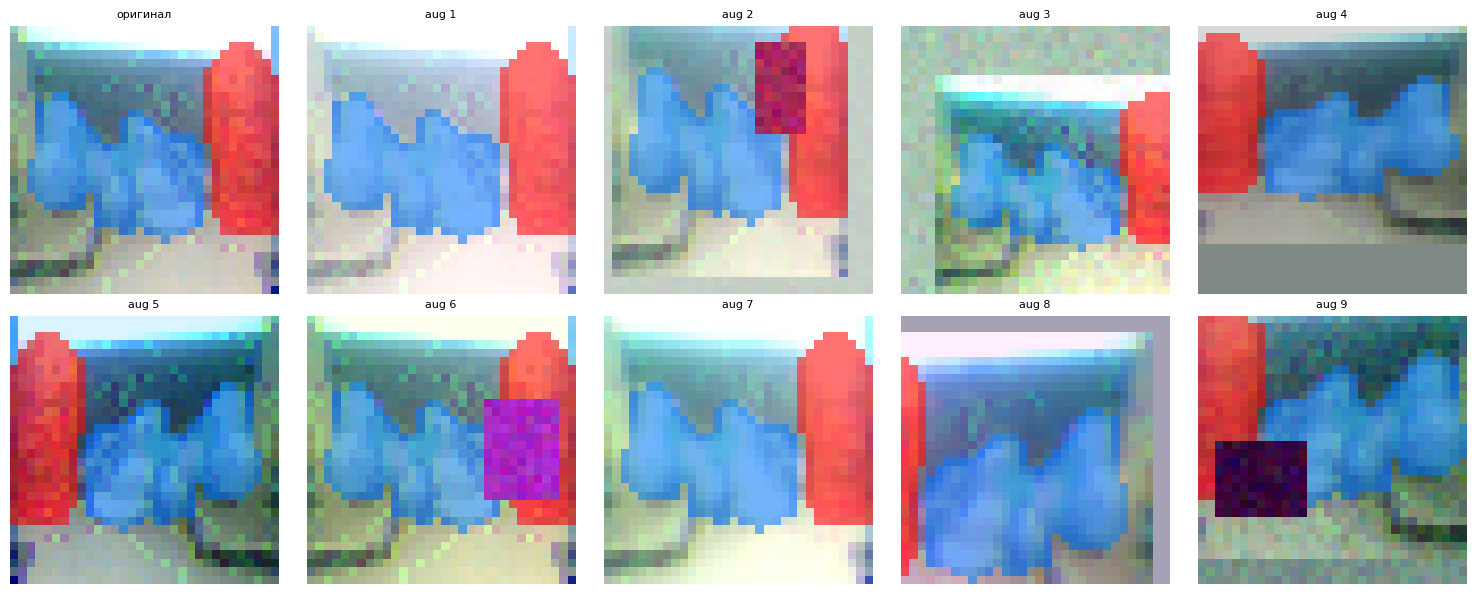

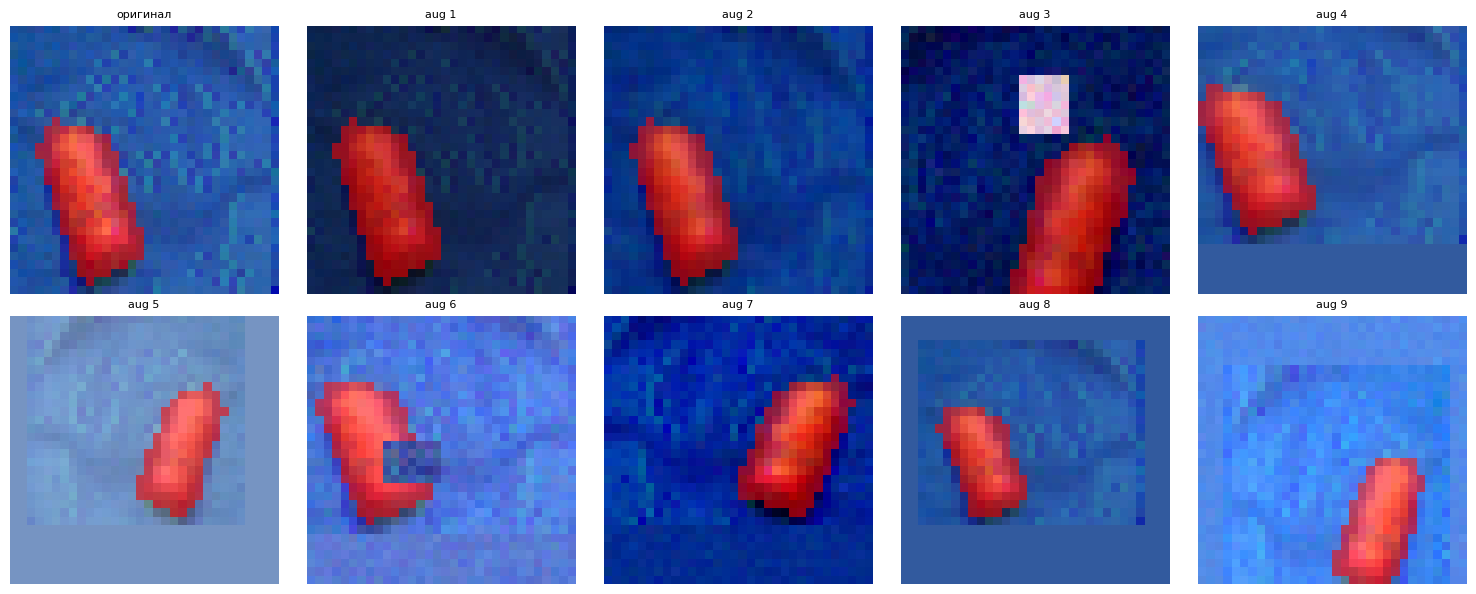

In [8]:
def show_augmentations(data, idx=0, n=10, seed=1):
    rng = np.random.default_rng(seed)
    img0 = data["images"][idx].astype(np.float32) / 255.0; m0 = data["masks"][idx].astype(np.float32)
    fig, axes = plt.subplots(2, n // 2, figsize=(3 * n // 2, 6))
    for k, ax in enumerate(axes.ravel()):
        im, mk = (img0, m0) if k == 0 else augment_one(img0, m0, rng, CFG["aug"])
        ax.imshow(overlay_masks((im * 255).astype(np.uint8), mk), interpolation="nearest"); ax.axis("off")
        ax.set_title("оригинал" if k == 0 else "aug %d" % k, fontsize=8)
    plt.tight_layout(); plt.show()

_fg = np.where(train_data["masks"].reshape(len(train_data["masks"]), -1).any(1))[0]
show_augmentations(train_data, int(_fg[0])); show_augmentations(train_data, int(_fg[len(_fg) // 2]), seed=5)

# Шаг 3. Метрики сегментации и подбор порога
Метрики считаются **на уровне всего набора** (TP/FP/FN суммируются по всем кадрам и пикселям), отдельно для каждого класса:
* **IoU** и **Dice** по классам, **mIoU** — среднее IoU по классам (главная метрика отбора лучшей эпохи);
* **Precision / Recall** по классам;
* **IoU по кадрам** (среднее по кадрам, где класс присутствует) — показывает разброс качества;
* **ложные срабатывания на фоне:** доля кадров без объектов, где предсказано хотя бы `min_fp_px` пикселей, и среднее число ложных пикселей на такой кадр.

Если класса нет ни в разметке, ни в предсказании (TP+FP+FN = 0), его IoU считается равным 1. Порог вероятности подбирается **для каждого класса отдельно** по IoU на val (IoU класса зависит только от его порога).

In [9]:
# Метрики сегментации. prob: [N,H,W,C] вероятности; gt: [N,H,W,C] 0/1; thr: число или вектор [C].
def seg_metrics(prob, gt, thr=0.5, min_fp_px=1):
    thr = np.broadcast_to(np.asarray(thr, np.float32), (prob.shape[-1],))
    pred = prob >= thr; g = gt > 0.5
    tp = (pred & g).sum((0, 1, 2)).astype(np.float64); fp = (pred & ~g).sum((0, 1, 2)).astype(np.float64); fn = (~pred & g).sum((0, 1, 2)).astype(np.float64)
    den = tp + fp + fn
    iou = np.where(den == 0, 1.0, tp / np.maximum(den, 1)); dice = np.where(den == 0, 1.0, 2 * tp / np.maximum(2 * tp + fp + fn, 1))
    prec = tp / np.maximum(tp + fp, 1); rec = tp / np.maximum(tp + fn, 1)
    inter = (pred & g).sum((1, 2)).astype(np.float64); union = (pred | g).sum((1, 2)).astype(np.float64); present = g.any((1, 2))   # [N, C]
    img_iou = np.array([(inter[present[:, c], c] / np.maximum(union[present[:, c], c], 1)).mean() if present[:, c].any() else np.nan for c in range(prob.shape[-1])])
    bg = ~g.any((1, 2, 3)); n_bg = int(bg.sum()); bg_px = pred[bg].sum((1, 2, 3)) if n_bg else np.zeros(0)
    return dict(iou=iou, dice=dice, prec=prec, rec=rec, img_iou=img_iou, miou=float(iou.mean()), mdice=float(dice.mean()),
                n_bg=n_bg, bg_fp_frames=float((bg_px >= min_fp_px).mean()) if n_bg else 0.0, bg_fp_px=float(bg_px.mean()) if n_bg else 0.0)

def fmt_seg(m):
    per = " | ".join("%s IoU %.3f P %.3f R %.3f" % (FG[c][:4], m["iou"][c], m["prec"][c], m["rec"][c]) for c in range(len(FG)))
    return "mIoU %.3f mDice %.3f | %s | фон: ложных кадров %.1f %% (%.1f px/кадр, n=%d)" % (m["miou"], m["mdice"], per, 100 * m["bg_fp_frames"], m["bg_fp_px"], m["n_bg"])

# Подбор порога вероятности для каждого класса по IoU на val.
def tune_thresholds(prob, gt, grid=np.round(np.arange(0.1, 0.91, 0.05), 2)):
    ious = np.stack([seg_metrics(prob, gt, t)["iou"] for t in grid])             # [G, C]
    best = ious.argmax(0); return np.array([grid[b] for b in best], np.float32), grid, ious

def np_sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -30, 30)))

# Шаг 4. Генератор батчей
`SegBatcher` — связующее звено между датасетом, аугментацией и TensorFlow. В отличие от детекции здесь не нужны ни анкоры, ни тепловые карты: цель — сама маска `[B, 32, 32, NumClasses]`, поэтому никаких «целевых функций» на стороне NumPy не требуется. Обучающий батчер перемешивает данные, применяет аугментацию и мозаику; валидационный — отдаёт кадры как есть.

In [10]:
class SegBatcher:
    def __init__(self, data, batch_size, train, aug=None, seed=0):
        self.d, self.bs, self.train, self.aug = data, batch_size, train, aug
        self.rng = np.random.default_rng(seed); self.n = len(data["images"])
    def __len__(self):
        return max(1, self.n // self.bs) if self.train else int(math.ceil(self.n / self.bs))
    def _get(self, i):
        return self.d["images"][i].astype(np.float32) / 255.0, self.d["masks"][i].astype(np.float32)
    def _sample(self, i):
        img, msk = self._get(i)
        if not self.train: return img, msk
        a = self.aug
        if a["p_mosaic"] > 0 and self.rng.random() < a["p_mosaic"]:
            ids = [i] + list(self.rng.integers(0, self.n, 3)); self.rng.shuffle(ids)
            quiet = dict(a, p_erase=0.0, p_noise=0.0, p_blur=0.0)
            return mosaic4([augment_one(*self._get(int(j)), self.rng, quiet) for j in ids])
        return augment_one(img, msk, self.rng, a)
    def __iter__(self):
        idx = self.rng.permutation(self.n) if self.train else np.arange(self.n)
        for s in range(0, len(self) * self.bs if self.train else self.n, self.bs):
            xs, ys = [], []
            for i in idx[s:s + self.bs]:
                img, msk = self._sample(int(i)); xs.append(img); ys.append(msk)
            yield np.stack(xs).astype(np.float32), np.stack(ys).astype(np.float32)

# Шаг 5. Архитектура UNet поверх backbone

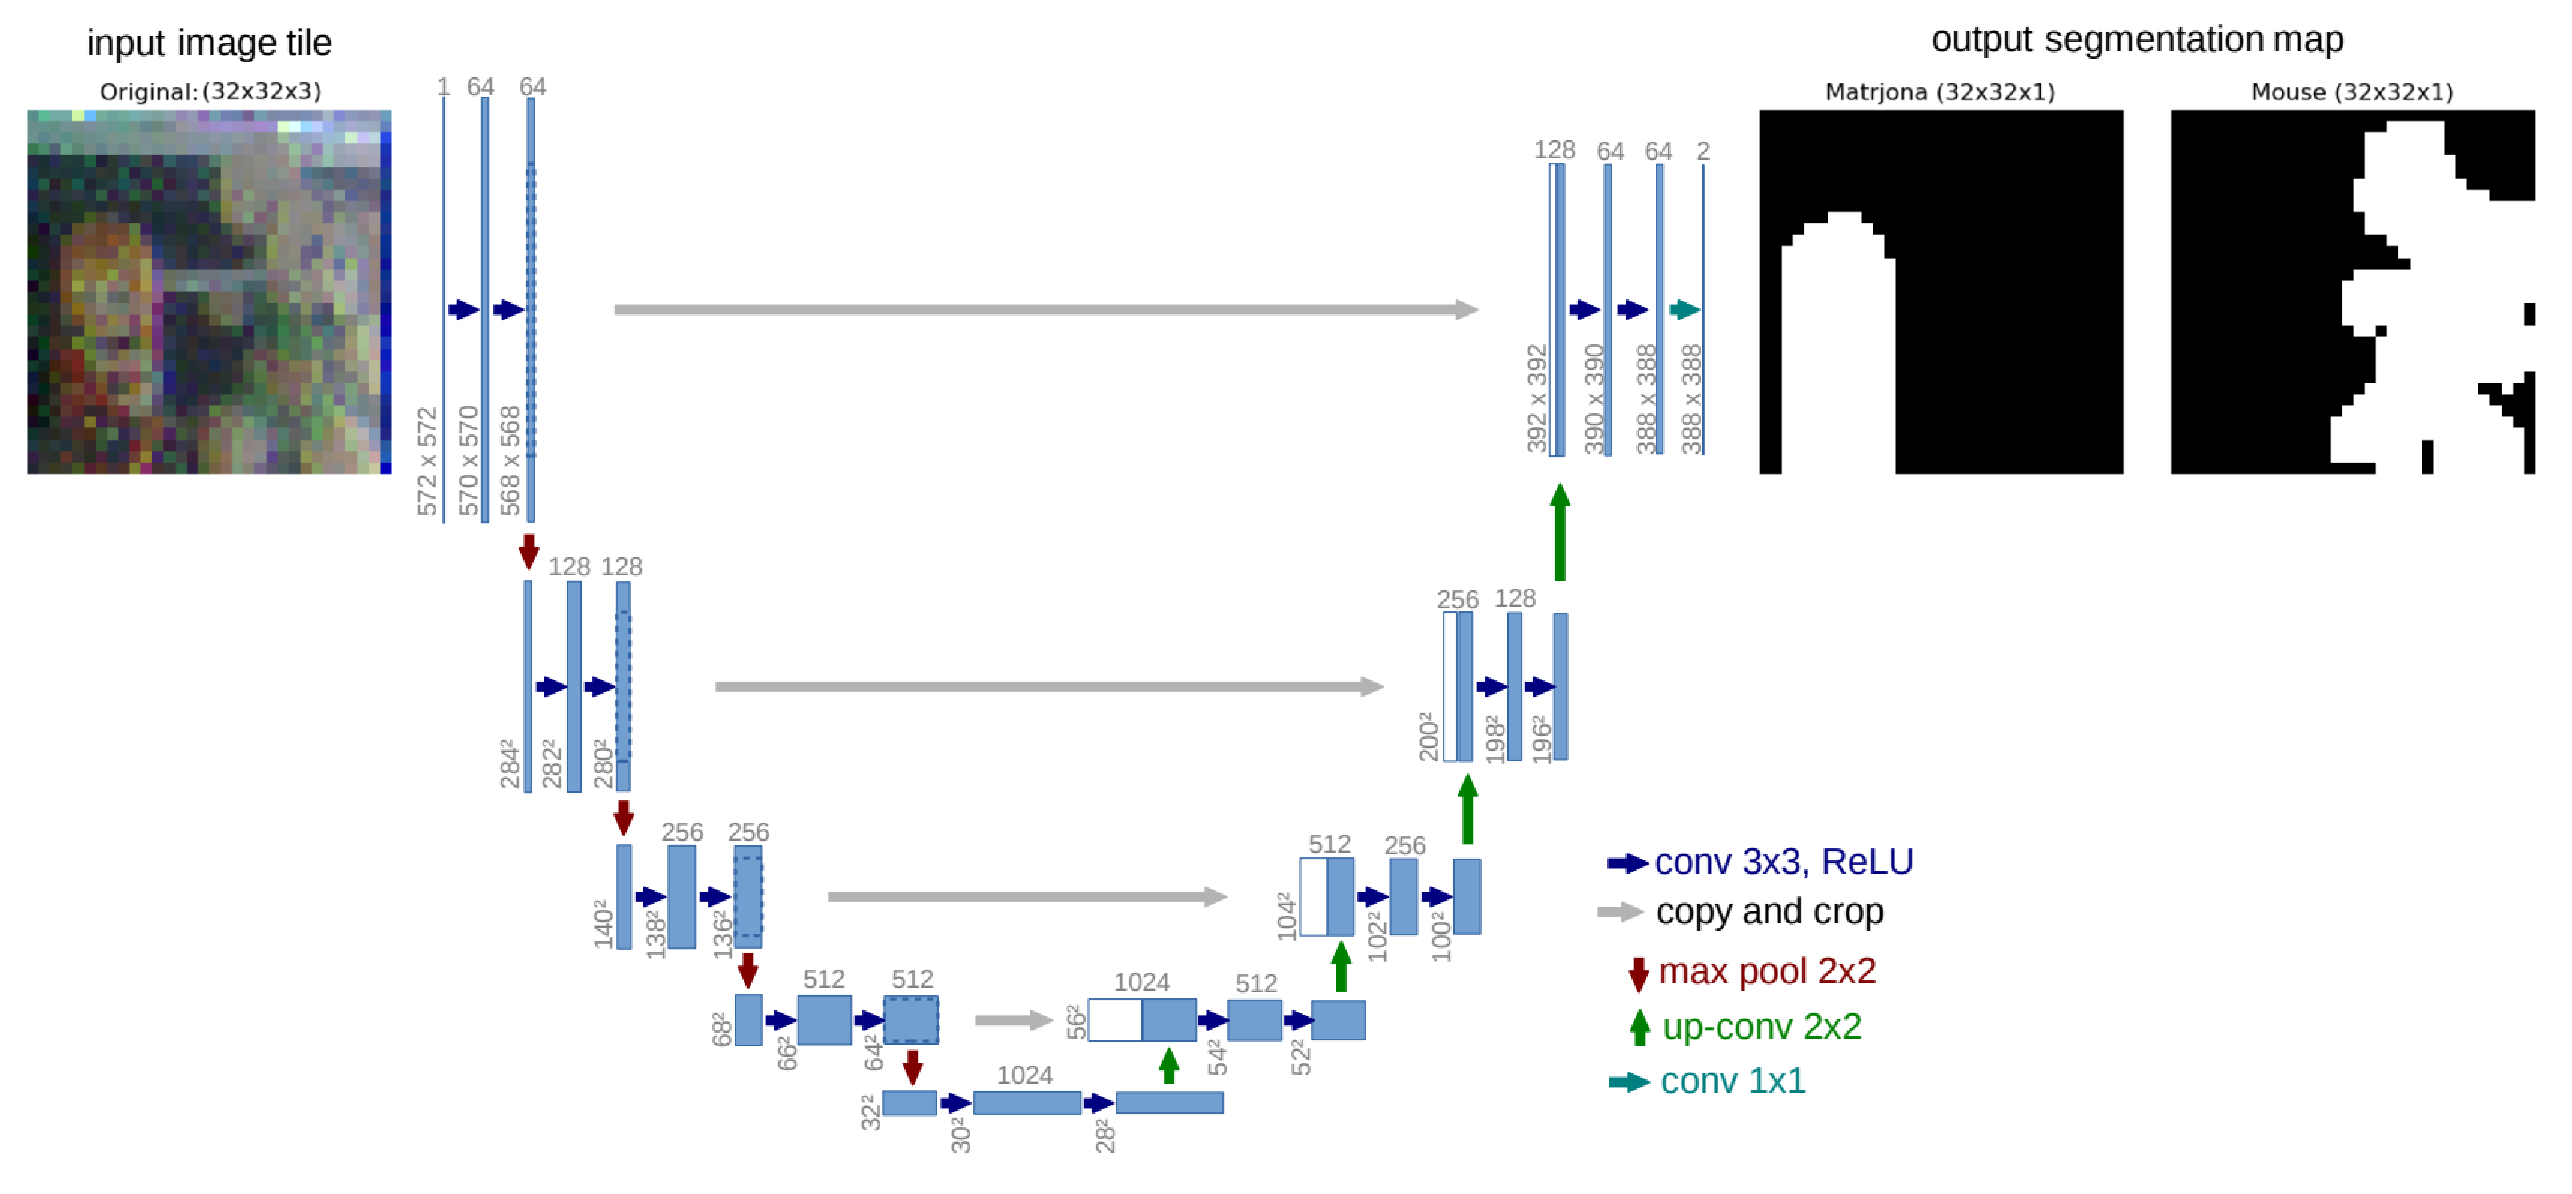

Поверх backbone строится UNet декодер, который за счёт конкатенация карт признаков через skip connection от backbone генерирует маски для классов. Используются четыре уровня (bottleneck + три kip connection), в результате маски для классов доводится до полного разрешения 32×32.

```
input 32x32x3
  stem: conv3x3 -> 32x32x16 + BN+ReLU6                         # skip stem (32x32x16)
  down -> 16x16 (pool0 2x2) + dw3x3+pw -> 16x16x32 + BN+ReLU6  # skip s0b0 (16x16x32)
  down -> 8x8   (pool1 2x2) + dw3x3+pw -> 8x8x64   + BN+ReLU6  # skip s1b0 (8x8x64)
  down -> 4x4   (pool2 2x2) + dw3x3+pw -> 4x4x128  + BN+ReLU6
bottleneck 4x4x128 --1x1--> 4x4x64
   up -> 8x8   + skip s1b0 (8x8x64  -> 1x1 -> 16)  -> dw3x3+pw -> 8x8x32
   up -> 16x16 + skip s0b0 (16x16x32-> 1x1 -> 16)  -> dw3x3+pw -> 16x16x16
   up -> 32x32 + skip stem (32x32x16-> 1x1 -> 8)   -> dw3x3+pw -> 32x32x16
   1x1 conv -> 32x32xNumClasses (логиты, sigmoid применяется в функции потерь / порогом на МК)
```


In [13]:
L = tf.keras.layers

# Планировщик скорости обучения (нужен и для загрузки .h5 бэкбона, в котором он сериализован, и для обучения).
class WarmupCosine(tf.keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, peak, total_steps, warmup_steps, floor=1e-5):
        super().__init__()
        self.peak, self.total, self.warmup, self.floor = float(peak), float(total_steps), float(warmup_steps), float(floor)
    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warm = self.peak * (step + 1.0) / max(1.0, self.warmup)
        prog = tf.clip_by_value((step - self.warmup) / max(1.0, self.total - self.warmup), 0.0, 1.0)
        cosine = self.floor + (self.peak - self.floor) * 0.5 * (1.0 + tf.cos(math.pi * prog))
        return tf.where(step < self.warmup, warm, cosine)
    def get_config(self):
        return dict(peak=self.peak, total_steps=self.total, warmup_steps=self.warmup, floor=self.floor)

# Загрузка базовой сети.
def load_backbone(path, pretrained=True):
    bb = tf.keras.models.load_model(path, compile=False, custom_objects={"WarmupCosine": WarmupCosine})
    if not pretrained:      # абляция: та же архитектура, но случайные веса
        bb = tf.keras.models.clone_model(bb)
    return bb

# Базовый строительный свёрточный блок (conv/dw -> BN -> ReLU6), как в детекции.
def cbr(x, ch, k, name, dw=False, act=True):
    if dw:
        x = L.DepthwiseConv2D(k, padding="same", use_bias=False, name=name + "_dw")(x)
    else:
        x = L.Conv2D(ch, k, padding="same", use_bias=False, name=name + "_conv")(x)
    x = L.BatchNormalization(name=name + "_bn")(x)
    return L.ReLU(6.0, name=name + "_relu6")(x) if act else x

# Один уровень декодера: апсемплинг x вдвое, объединение со скипом, затем blocks раз (dw3x3 + pw1x1).
def dec_level(x, skip, ch, skip_ch, merge, blocks, name):
    if merge == "add":
        # FPN-вариант: приводим x и скип к ch каналам и складываем (экономит RAM, но скип смешивается с апсемплом).
        x = cbr(x, ch, 1, name + "_lat")
        y = L.Add(name=name + "_add")([L.UpSampling2D(2, interpolation="nearest", name=name + "_up")(x), cbr(skip, ch, 1, name + "_skip")])
    elif merge == "concat":
        up = L.UpSampling2D(2, interpolation="nearest", name=name + "_up")(x)
        s = cbr(skip, skip_ch, 1, name + "_skip") if skip_ch > 0 else skip
        y = L.Concatenate(axis=-1, name=name + "_cat")([up, s])
    else:
        raise ValueError("merge должен быть 'concat' или 'add'")
    for b in range(blocks):
        y = cbr(cbr(y, 0, 3, "%s_b%d_d" % (name, b), dw=True), ch, 1, "%s_b%d_p" % (name, b))
    return y

# Сборка UNet поверх backbone по параметрам CFG["unet"].
def build_unet(backbone, cfg):
    uc = cfg["unet"]
    assert len(uc["skips"]) == len(uc["dec_ch"]) == len(uc["skip_ch"]), "skips, skip_ch и dec_ch должны быть одной длины"
    if not cfg["backbone"]["trainable"]:
        for l in backbone.layers: l.trainable = False          # заморозка (BN переходит в inference-режим)
    x = backbone.get_layer(uc["bottleneck"]).output
    if uc["bottleneck_ch"]:
        x = cbr(x, uc["bottleneck_ch"], 1, "bott")
    for k, name in enumerate(uc["skips"]):
        s = backbone.get_layer(name).output
        assert int(s.shape[1]) == 2 * int(x.shape[1]), "скип %s (%s) должен быть вдвое крупнее текущей карты %s" % (name, tuple(s.shape[1:3]), tuple(x.shape[1:3]))
        x = dec_level(x, s, uc["dec_ch"][k], uc["skip_ch"][k], uc["merge"], uc["blocks"], "dec%d" % k)
    out = L.Conv2D(NC, 1, padding="same", bias_initializer=tf.keras.initializers.Constant(uc["out_bias"]), name="seg_logits")(x)
    f = IMG // int(out.shape[1])
    if f > 1:                                                   # неполное разрешение -> растягиваем логиты до 32x32
        out = L.UpSampling2D(f, interpolation="nearest", name="seg_up")(out)
    return tf.keras.Model(backbone.input, out, name="unet_seg")

# Проверка и извлечение карт признаков (Feature Maps).
backbone = load_backbone(CFG["paths"]["backbone"], CFG["backbone"]["pretrained"])
assert tuple(backbone.input_shape[1:]) == (IMG, IMG, 3)
print("Backbone:", backbone.name, "| вход", backbone.input_shape, "| параметров", backbone.count_params())
for t in (CFG["unet"]["bottleneck"],) + tuple(CFG["unet"]["skips"]):
    print("  отвод %-16s -> %s" % (t, backbone.get_layer(t).output_shape[1:]))
_probe = build_unet(load_backbone(CFG["paths"]["backbone"], CFG["backbone"]["pretrained"]), CFG)
_probe.summary(line_length=110)
print("UNet: параметров %s (~%.1f КБ в int8), выход %s" % (format(_probe.count_params(), ","), _probe.count_params() / 1024, _probe.output_shape))
del _probe

Backbone: cnn_medium | вход (None, 32, 32, 3) | параметров 13987
  отвод s2b0_pw_relu6    -> (4, 4, 128)
  отвод s1b0_pw_relu6    -> (8, 8, 64)
  отвод s0b0_pw_relu6    -> (16, 16, 32)
  отвод stem_relu6       -> (32, 32, 16)
Model: "unet_seg"
______________________________________________________________________________________________________________
 Layer (type)                    Output Shape                     Param #    Connected to                     
 input (InputLayer)              [(None, 32, 32, 3)]              0          []                               
                                                                                                              
 stem_conv (Conv2D)              (None, 32, 32, 16)               432        ['input[0][0]']                  
                                                                                                              
 stem_bn (BatchNormalization)    (None, 32, 32, 16)               64         ['stem_conv[0

# Шаг 6. Утилиты TFLite и оценка памяти (арены) до обучения
Перед тем как приступить к обучению, полезно сразу узнать, сколько RAM потребует выбранная конфигурация `CFG["unet"]`. Для этого необученная модель конвертируется в INT8 (веса не важны, важны формы тензоров) и оценивается пик одновременно живых активаций по времени жизни тензоров: тензор живёт от операции, которая его создаёт, до последней операции, которая его читает.

Это нижняя оценка, точное значение смотрите на плате через `arena_used_bytes()`.

In [14]:
# Калибровочная выборка для квантователя: реальные кадры train + фотометрически искажённые копии.
def make_representative(n, seed=0):
    rng = np.random.default_rng(seed); imgs = train_data["images"]; idx = rng.permutation(len(imgs))
    xs = [imgs[i].astype(np.float32) / 255.0 for i in idx[:n]]
    photo_only = dict(CFG["aug"], p_photo=1.0)
    for i in idx[: n // 3]:
        xs.append(photometric(imgs[i].astype(np.float32) / 255.0, rng, photo_only))
    return np.stack(xs).astype(np.float32)

# Конвертация модели Keras в .tflite с полным квантованием в INT8 (PTQ).
def convert_int8(keras_model, calib):
    inp = tf.keras.Input(shape=keras_model.input_shape[1:], batch_size=1)      # статический batch = 1
    static = tf.keras.Model(inp, keras_model(inp))
    conv = tf.lite.TFLiteConverter.from_keras_model(static)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    conv.representative_dataset = lambda: ([c[None, ...]] for c in calib)
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    conv.inference_input_type = tf.int8; conv.inference_output_type = tf.int8
    return conv.convert()

# Чистая функция: пик суммы байт одновременно живых активаций.
def peak_live_bytes(ops, nbytes, in_ids, out_ids):
    """ops: список dict(inputs, outputs); nbytes: {id тензора: байт} только для активаций. Возвращает (пик, индекс операции пика)."""
    n = len(ops); birth, death = {}, {}
    for t in in_ids:
        if t in nbytes: birth[t] = 0; death[t] = 0
    for k, op in enumerate(ops):
        for t in op["outputs"]:
            if t in nbytes: birth.setdefault(t, k); death[t] = max(death.get(t, k), k)
        for t in op["inputs"]:
            if t in nbytes: death[t] = max(death.get(t, k), k)
    for t in out_ids:
        if t in nbytes: death[t] = n - 1
    peak, where = 0, 0
    for k in range(n):
        s = sum(nbytes[t] for t in birth if birth[t] <= k <= death[t])
        if s > peak: peak, where = s, k
    return peak, where

# Нижняя оценка арены (пик живых активаций) для .tflite.
def arena_lower_bound(blob):
    it = tf.lite.Interpreter(model_content=blob); it.allocate_tensors()
    det = {d["index"]: d for d in it.get_tensor_details()}; ops_ = it._get_ops_details()
    in_ids = [d["index"] for d in it.get_input_details()]; out_ids = [d["index"] for d in it.get_output_details()]
    produced = {t for op in ops_ for t in op["outputs"] if t >= 0}
    acts = produced | set(in_ids)                                                # всё остальное — константы (веса, bias)
    nbytes = {t: int(np.prod(det[t]["shape"])) * np.dtype(det[t]["dtype"]).itemsize for t in acts if t in det}
    peak, k = peak_live_bytes([dict(inputs=[i for i in op["inputs"] if i >= 0], outputs=[o for o in op["outputs"] if o >= 0]) for op in ops_], nbytes, in_ids, out_ids)
    return peak, k, ops_[k]["op_name"] if ops_ else "-"

# Функция извлекает список всех операций (слоев), которые используются в данной .tflite модели.
def interpreter_ops(blob):
    it = tf.lite.Interpreter(model_content=blob)
    try: return [d["op_name"] for d in it._get_ops_details()]
    except Exception as e:
        print("(_get_ops_details недоступен:", e, ")"); return []

# Словарь соответствий между операциями TensorFlow Lite и методами MicroMutableOpResolver в TFLM.
TFLM_OP = {"CONV_2D": "AddConv2D", "DEPTHWISE_CONV_2D": "AddDepthwiseConv2D", "MAX_POOL_2D": "AddMaxPool2D", "AVERAGE_POOL_2D": "AddAveragePool2D",
           "ADD": "AddAdd", "RESHAPE": "AddReshape", "CONCATENATION": "AddConcatenation", "RESIZE_NEAREST_NEIGHBOR": "AddResizeNearestNeighbor",
           "RESIZE_BILINEAR": "AddResizeBilinear", "TRANSPOSE_CONV": "AddTransposeConv",
           "QUANTIZE": "AddQuantize", "DEQUANTIZE": "AddDequantize", "PAD": "AddPad", "RELU": "AddRelu", "RELU6": "AddRelu6", "LOGISTIC": "AddLogistic",
           "SOFTMAX": "AddSoftmax", "FULLY_CONNECTED": "AddFullyConnected", "MEAN": "AddMean", "TRANSPOSE": "AddTranspose", "STRIDED_SLICE": "AddStridedSlice",
           "PACK": "AddPack", "SHAPE": "AddShape", "MUL": "AddMul", "SUB": "AddSub", "EXP": "AddExp"}

# Фрагмент кода на C++ для регистрации только тех операций, которые задействованы в модели.
def resolver_snippet(op_names):
    ops = sorted(set(op_names)); unknown = [o for o in ops if o not in TFLM_OP]
    body = "\n".join("\tmicro_op_resolver.%s();" % TFLM_OP[o] for o in ops if o in TFLM_OP)
    s = "static tflite::MicroMutableOpResolver<%d> micro_op_resolver;\n%s" % (len(ops) - len(unknown), body)
    return s + ("\n/* ВНИМАНИЕ: нет сопоставления для %s — добавить вручную */" % unknown if unknown else "")

# Быстрая оценка размера модели и арены для выбранной архитектуры ДО обучения (веса случайные, важны только формы тензоров).
def quick_budget(cfg, tag=""):
    m = build_unet(load_backbone(cfg["paths"]["backbone"], cfg["backbone"]["pretrained"]), cfg)
    blob = convert_int8(m, make_representative(48)); peak, k, opn = arena_lower_bound(blob)
    print("%s параметров %s | .tflite %.1f КБ | пик живых активаций ~%.1f КБ (операция #%d %s) | операции: %s" % (
        tag, format(m.count_params(), ","), len(blob) / 1024, peak / 1024, k, opn, sorted(set(interpreter_ops(blob)))))
    return peak

quick_budget(CFG, "[CFG по умолчанию]")

INFO:tensorflow:Assets written to: C:\Users\STEPAN~1\AppData\Local\Temp\tmp47bhdwtm\assets


INFO:tensorflow:Assets written to: C:\Users\STEPAN~1\AppData\Local\Temp\tmp47bhdwtm\assets
c:\Users\STEPANJUK\.conda\envs\STEP1\lib\site-packages\tensorflow\lite\python\convert.py:887: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


[CFG по умолчанию] параметров 29,850 | .tflite 58.2 КБ | пик живых активаций ~99.0 КБ (операция #24 DEPTHWISE_CONV_2D) | операции: ['CONCATENATION', 'CONV_2D', 'DEPTHWISE_CONV_2D', 'MAX_POOL_2D', 'RESIZE_NEAREST_NEIGHBOR']


101376

# Шаг 7. Функции потерь
Выход модели — логиты `[B, 32, 32, NumClasses]`, каждый канал — независимая бинарная задача «пиксель принадлежит классу» (классы могут перекрываться). Итоговая функция потерь: `w_bce*BCE + w_dice*Dice + w_focal*Focal`.

* **BCE** — устойчивая `sigmoid_cross_entropy_with_logits`; усредняется по пикселям отдельно для каждого класса, затем по классам.
* **Dice** считается **по всему батчу** и по каждому классу (суммы по батчу и пикселям), а не по каждому кадру: так кадры фона (пустые маски) не дают деления 0/0 и не ломают градиент. Он компенсирует дисбаланс «мало объектов / много фона», на который BCE чувствительна.
* **Focal** (по умолчанию выключен, `w_focal=0`) — для сравнения: ослабляет вклад лёгких пикселей.

Основа здесь — Dice, а BCE (вес 1.0) добавлена как стабилизатор: она даёт гладкий градиент в начале обучения, пока предсказания далеки от масок, и штрафует ложные срабатывания на пустых кадрах. Это сочетание — обычная практика (nnU-Net использует Dice + кросс-энтропию).

In [15]:
# Фабрика функции потерь. logits: [B,H,W,C], y: [B,H,W,C] 0/1 (float32). Возвращает dict(total, bce, dice, focal).
def make_seg_loss(cfg):
    lc = cfg["loss"]
    def loss_fn(logits, y):
        logits = tf.cast(logits, tf.float32); p = tf.sigmoid(logits)
        ce = tf.nn.sigmoid_cross_entropy_with_logits(labels=y, logits=logits)
        bce = tf.reduce_mean(tf.reduce_mean(ce, axis=[0, 1, 2]))                                      # по пикселям, затем по классам
        inter = tf.reduce_sum(p * y, axis=[0, 1, 2]); den = tf.reduce_sum(p, axis=[0, 1, 2]) + tf.reduce_sum(y, axis=[0, 1, 2])
        dice = 1.0 - tf.reduce_mean((2.0 * inter + lc["dice_smooth"]) / (den + lc["dice_smooth"]))   # batch-level Dice по классам
        pt = y * p + (1.0 - y) * (1.0 - p); at = y * lc["focal_alpha"] + (1.0 - y) * (1.0 - lc["focal_alpha"])
        focal = tf.reduce_mean(at * tf.pow(1.0 - pt, lc["focal_gamma"]) * ce)
        total = lc["w_bce"] * bce + lc["w_dice"] * dice + lc["w_focal"] * focal
        return dict(total=total, bce=bce, dice=dice, focal=focal)
    return loss_fn

# Шаг 8. Обучение
`SegTrainer` повторяет `Trainer` из детекции: два оптимизатора AdamW (меньший learning rate для бэкбона, больший для декодера), warmup + cosine, clipping градиентов, EMA весов и ранняя остановка. Отличия — только в задаче:
* лучшая эпоха выбирается по **val mIoU** (при пороге `CFG["post"]["thr"]`; при равенстве — по val-потерям);
* на каждой эпохе считаются IoU по классам и доля ложных срабатываний на фоновых кадрах;
* если `CFG["backbone"]["trainable"] = False`, оптимизатор бэкбона не используется, а его BatchNorm работают в inference-режиме.

In [16]:
# Предсказание логитов Keras-моделью для набора uint8-изображений.
def predict_logits_keras(model, images_u8, bs=256):
    out = [model(images_u8[s:s + bs].astype(np.float32) / 255.0, training=False).numpy() for s in range(0, len(images_u8), bs)]
    return np.concatenate(out) if out else np.zeros((0, IMG, IMG, NC), np.float32)

class SegTrainer:
    def __init__(self, cfg, backbone_model, train_d, val_d):
        self.cfg, self.tc = cfg, cfg["train"]; self.train_d, self.val_d = train_d, val_d
        self.model = build_unet(backbone_model, cfg); self.loss_fn = make_seg_loss(cfg)
        bb_names = {l.name for l in backbone_model.layers}
        self.bb_vars = [v for l in self.model.layers if l.name in bb_names for v in l.trainable_variables]
        bb_ids = {id(v) for v in self.bb_vars}
        self.hd_vars = [v for v in self.model.trainable_variables if id(v) not in bb_ids]
        self.train_batcher = SegBatcher(train_d, self.tc["batch_size"], True, cfg["aug"], self.tc["seed"])
        steps = len(self.train_batcher) * self.tc["epochs"]; wu = len(self.train_batcher) * self.tc["warmup_epochs"]
        self.sched_bb = WarmupCosine(self.tc["lr_backbone"], steps, wu, self.tc["lr_backbone"] * self.tc["min_lr_ratio"])
        self.sched_hd = WarmupCosine(self.tc["lr_head"], steps, wu, self.tc["lr_head"] * self.tc["min_lr_ratio"])
        mk = lambda sch: tf.keras.optimizers.AdamW(learning_rate=sch, weight_decay=self.tc["weight_decay"])
        self.opt_bb, self.opt_hd = mk(self.sched_bb), mk(self.sched_hd)
        for o in (self.opt_bb, self.opt_hd):
            try: o.exclude_from_weight_decay(var_names=["bn", "bias", "beta", "gamma"])
            except Exception: pass
        self.ema = [tf.Variable(w, trainable=False) for w in self.model.weights]; self.ema_steps = tf.Variable(0.0, trainable=False)
        self.history = {k: [] for k in ("loss", "bce", "dice", "val_loss", "val_miou", "val_mdice", "val_iou", "val_bg_fp", "lr")}
        self.best = dict(score=-1.0, loss=1e9, epoch=-1)
        self.ckpt = str(OUT_DIR / "unet_best.h5")

        @tf.function(reduce_retracing=True)
        def train_step(x, y):
            with tf.GradientTape() as tape:
                logits = self.model(x, training=True); ls = self.loss_fn(logits, y)
            allv = self.bb_vars + self.hd_vars; g = tape.gradient(ls["total"], allv)
            g, _ = tf.clip_by_global_norm(g, self.tc["clip_norm"])
            nb = len(self.bb_vars)
            if nb: self.opt_bb.apply_gradients(zip(g[:nb], self.bb_vars))
            self.opt_hd.apply_gradients(zip(g[nb:], self.hd_vars))
            self.ema_steps.assign_add(1.0); d = tf.minimum(self.tc["ema_decay"], (1.0 + self.ema_steps) / (10.0 + self.ema_steps))
            for e, w in zip(self.ema, self.model.weights): e.assign(d * e + (1.0 - d) * w)
            return ls
        self.train_step = train_step

        @tf.function(reduce_retracing=True)
        def eval_step(x, y):
            logits = self.model(x, training=False); return logits, self.loss_fn(logits, y)
        self.eval_step = eval_step

    # Подменяет рабочие веса на сглаженные EMA-веса перед валидацией и возвращает обратно после неё.
    def _swap_in_ema(self):
        self._backup = self.model.get_weights(); self.model.set_weights([e.numpy() for e in self.ema])
    def _swap_out(self):
        self.model.set_weights(self._backup)

    # Прогон по всему набору: метрики сегментации + средняя функция потерь.
    def evaluate(self, data, thr=None):
        thr = self.cfg["post"]["thr"] if thr is None else thr; logits, losses = [], []
        for x, y in SegBatcher(data, 64, False):
            lg, ls = self.eval_step(x, y); logits.append(lg.numpy()); losses.append(float(ls["total"]) * len(x))
        m = seg_metrics(np_sigmoid(np.concatenate(logits)), data["masks"], thr, self.cfg["post"]["min_fp_px"])
        m["loss"] = sum(losses) / max(len(data["images"]), 1); return m

    # Основной цикл обучения.
    def fit(self, verbose=True):
        tc = self.tc; bad = 0; t0 = time.time(); h = self.history
        for ep in range(tc["epochs"]):
            run = {"total": [], "bce": [], "dice": []}
            for x, y in tqdm(self.train_batcher, desc="ep %d/%d" % (ep + 1, tc["epochs"]), leave=False):
                ls = self.train_step(x, y)
                for k in run: run[k].append(float(ls[k]))
                if not np.isfinite(run["total"][-1]): print("NaN loss — остановка"); return self.history
            self._swap_in_ema(); m = self.evaluate(self.val_d); score = m["miou"]
            improved = score > self.best["score"] + 1e-4 or (abs(score - self.best["score"]) <= 1e-4 and m["loss"] < self.best["loss"])
            if improved:
                self.best = dict(score=score, loss=m["loss"], epoch=ep); self.model.save_weights(self.ckpt); bad = 0
            else:
                bad += 1
            self._swap_out()
            h["loss"].append(float(np.mean(run["total"]))); h["bce"].append(float(np.mean(run["bce"]))); h["dice"].append(float(np.mean(run["dice"])))
            h["val_loss"].append(m["loss"]); h["val_miou"].append(m["miou"]); h["val_mdice"].append(m["mdice"]); h["val_iou"].append(list(m["iou"])); h["val_bg_fp"].append(m["bg_fp_frames"])
            h["lr"].append(float(self.sched_hd(self.opt_hd.iterations)))
            if verbose and (ep % 5 == 0 or improved):
                print("ep %3d | loss %.3f val %.3f | val mIoU %.3f mDice %.3f IoU %s | фон-FP %.1f %%%s (%.0fs)" % (
                    ep + 1, h["loss"][-1], m["loss"], m["miou"], m["mdice"], np.round(m["iou"], 3).tolist(), 100 * m["bg_fp_frames"], "  *best*" if improved else "", time.time() - t0))
            if bad >= tc["patience"]:
                print("ранняя остановка на эпохе %d; лучшая эпоха %d, val mIoU %.3f" % (ep + 1, self.best["epoch"] + 1, self.best["score"])); break
        self.model.load_weights(self.ckpt)          # лучшие (EMA) веса
        return self.history

### Запуск обучения

In [19]:
set_seed(CFG["train"]["seed"])
bb = load_backbone(CFG["paths"]["backbone"], CFG["backbone"]["pretrained"])   # свежий экземпляр бэкбона
trainer = SegTrainer(CFG, bb, train_data, val_data)
n_par = trainer.model.count_params(); print("UNet: параметров %s (~%.1f КБ в int8)" % (format(n_par, ","), n_par / 1024))
trainer.fit()
print("\nЛучшая эпоха %d: val mIoU %.3f" % (trainer.best["epoch"] + 1, trainer.best["score"]))

UNet: параметров 29,850 (~29.2 КБ в int8)


ep 1/150:   0%|          | 0/69 [00:00<?, ?it/s]

ep   1 | loss 1.073 val 1.254 | val mIoU 0.000 mDice 0.000 IoU [0.0, 0.0] | фон-FP 0.0 %  *best* (7s)


ep 2/150:   0%|          | 0/69 [00:00<?, ?it/s]

ep   2 | loss 0.723 val 1.247 | val mIoU 0.000 mDice 0.000 IoU [0.0, 0.0] | фон-FP 0.0 %  *best* (11s)


ep 3/150:   0%|          | 0/69 [00:00<?, ?it/s]

... (223 outputs left out)

ep 148/150:   0%|          | 0/69 [00:00<?, ?it/s]

ep 149/150:   0%|          | 0/69 [00:00<?, ?it/s]

ep 150/150:   0%|          | 0/69 [00:00<?, ?it/s]


Лучшая эпоха 136: val mIoU 0.721


### Кривые обучения
Слева — функция потерь (train/val), в центре — val IoU по классам и mIoU, справа — доля ложных кадров на фоне и learning rate.

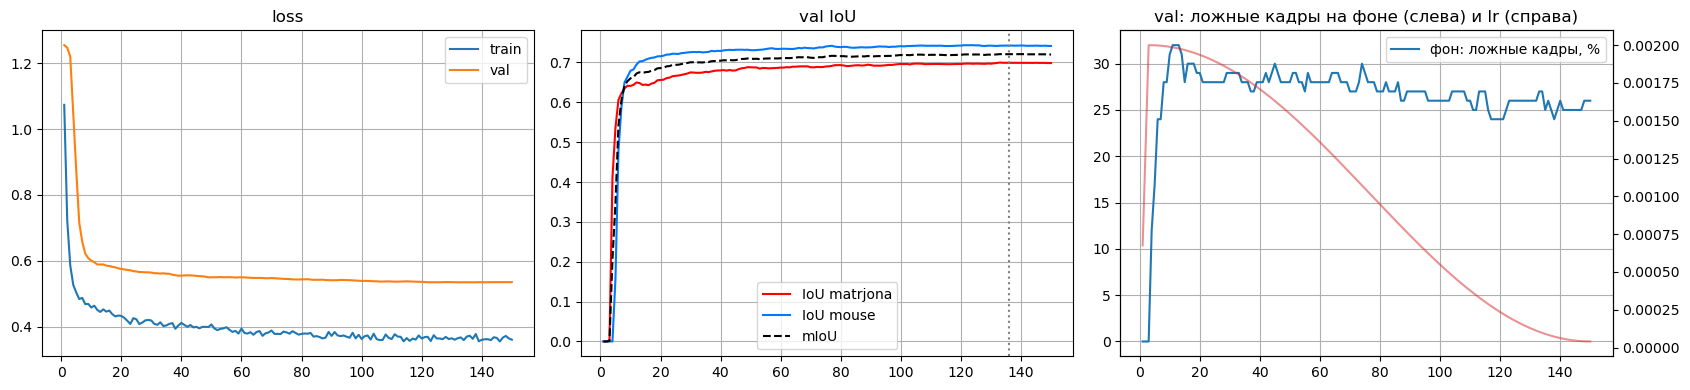

In [20]:
h = trainer.history; ep = np.arange(1, len(h["loss"]) + 1); iou = np.array(h["val_iou"])
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(ep, h["loss"], label="train"); ax[0].plot(ep, h["val_loss"], label="val"); ax[0].set_title("loss"); ax[0].legend(); ax[0].grid(True)
for c, nm in enumerate(FG): ax[1].plot(ep, iou[:, c], label="IoU " + nm, color=np.array(COLORS[c]) / 255.0)
ax[1].plot(ep, h["val_miou"], label="mIoU", color="k", ls="--"); ax[1].axvline(trainer.best["epoch"] + 1, color="gray", ls=":"); ax[1].set_title("val IoU"); ax[1].legend(); ax[1].grid(True)
ax[2].plot(ep, 100 * np.array(h["val_bg_fp"]), label="фон: ложные кадры, %"); ax[2].set_title("val: ложные кадры на фоне (слева) и lr (справа)"); ax[2].grid(True)
ax2 = ax[2].twinx(); ax2.plot(ep, h["lr"], color="tab:red", alpha=0.5); ax[2].legend()
plt.tight_layout(); plt.show()

# Шаг 9. Оценка float-модели (val / test), подбор порога
Пороги вероятности подбираются **по val для каждого класса** (максимум IoU класса), затем фиксируются и применяются к test и к INT8-модели. Таблица показывает метрики при пороге 0.5 и при подобранном пороге.

Подобранные пороги (по val): {'matrjona': 0.6000000238418579, 'mouse': 0.4000000059604645}
[val ] thr=0.50: mIoU 0.721 mDice 0.838 | matr IoU 0.699 P 0.817 R 0.830 | mous IoU 0.743 P 0.887 R 0.820 | фон: ложных кадров 26.0 % (12.8 px/кадр, n=100)
[val ] thr=tuned: mIoU 0.723 mDice 0.839 | matr IoU 0.700 P 0.834 R 0.813 | mous IoU 0.746 P 0.871 R 0.839 | фон: ложных кадров 27.0 % (12.4 px/кадр, n=100)
[test] thr=0.50: mIoU 0.700 mDice 0.823 | matr IoU 0.689 P 0.850 R 0.784 | mous IoU 0.711 P 0.862 R 0.802 | фон: ложных кадров 24.0 % (16.6 px/кадр, n=100)
[test] thr=tuned: mIoU 0.700 mDice 0.824 | matr IoU 0.687 P 0.866 R 0.769 | mous IoU 0.714 P 0.842 R 0.824 | фон: ложных кадров 25.0 % (15.8 px/кадр, n=100)
IoU по кадрам на test (только кадры с классом): {'matrjona': 0.746, 'mouse': 0.717}


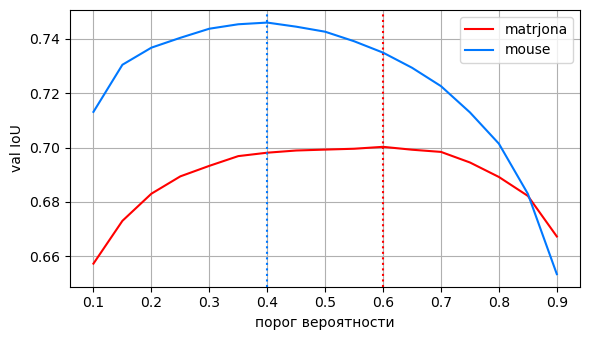

In [21]:
val_prob = np_sigmoid(predict_logits_keras(trainer.model, val_data["images"]))
test_prob = np_sigmoid(predict_logits_keras(trainer.model, test_data["images"]))
OP_THR, _grid, _ious = tune_thresholds(val_prob, val_data["masks"])
print("Подобранные пороги (по val):", dict(zip(FG, OP_THR.tolist())))
for split, d, pr in (("val", val_data, val_prob), ("test", test_data, test_prob)):
    print("[%-4s] thr=0.50: %s" % (split, fmt_seg(seg_metrics(pr, d["masks"], 0.5, CFG["post"]["min_fp_px"]))))
    print("[%-4s] thr=tuned: %s" % (split, fmt_seg(seg_metrics(pr, d["masks"], OP_THR, CFG["post"]["min_fp_px"]))))
m_t = seg_metrics(test_prob, test_data["masks"], OP_THR); print("IoU по кадрам на test (только кадры с классом):", dict(zip(FG, np.round(m_t["img_iou"], 3).tolist())))

fig, ax = plt.subplots(1, 1, figsize=(6, 3.5))
for c, nm in enumerate(FG): ax.plot(_grid, _ious[:, c], label=nm, color=np.array(COLORS[c]) / 255.0); ax.axvline(OP_THR[c], color=np.array(COLORS[c]) / 255.0, ls=":")
ax.set_xlabel("порог вероятности"); ax.set_ylabel("val IoU"); ax.grid(True); ax.legend(); plt.tight_layout(); plt.show()

### Визуализация предсказаний на тестовой выборке
Верхний блок — случайные кадры, нижний — кадры с наибольшим числом ошибочных пикселей. В заголовках — число ошибочных пикселей (FP+FN).

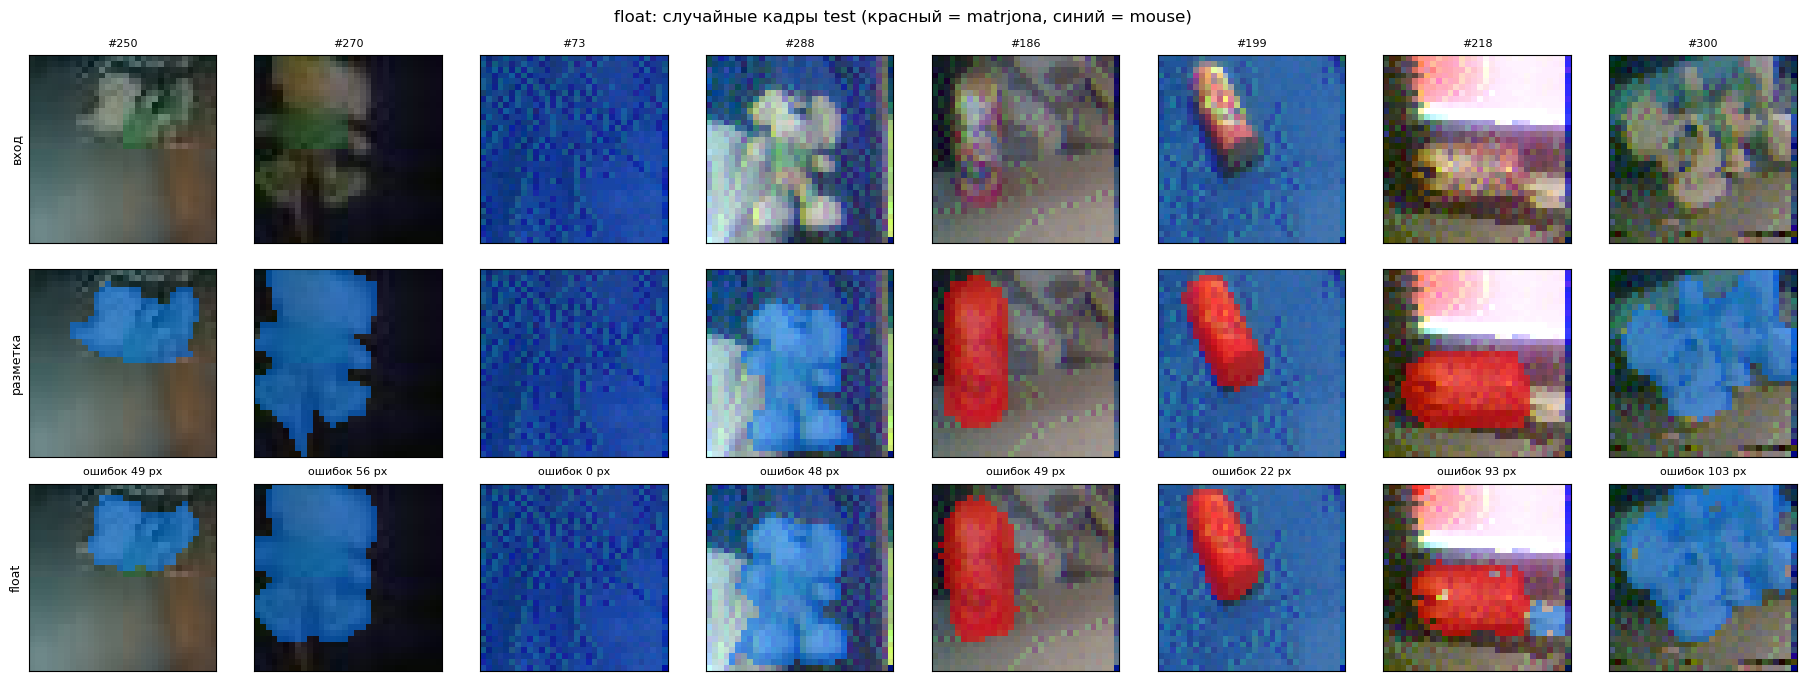

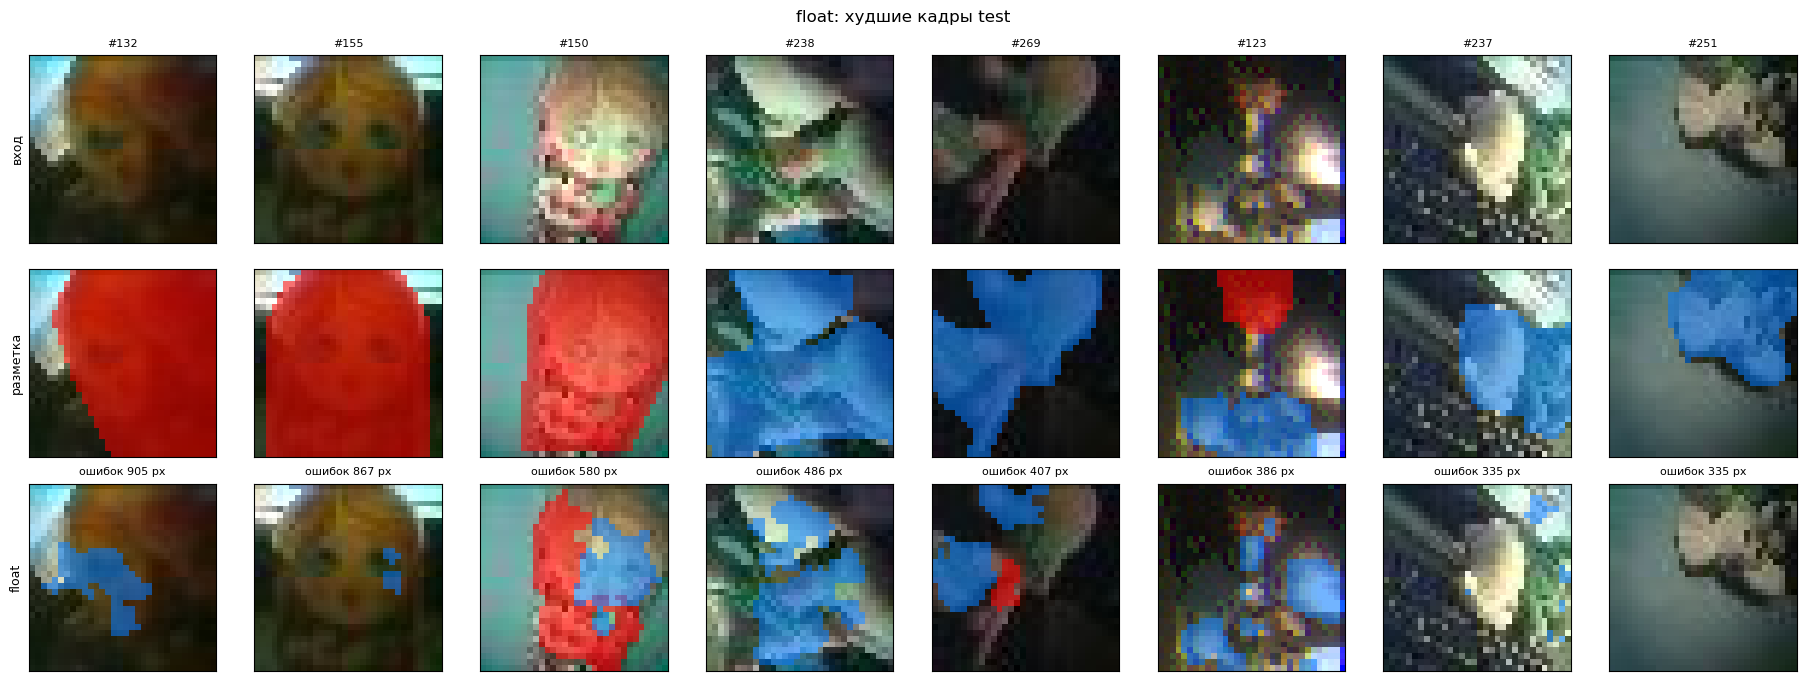

In [22]:
# Сетка: вход / разметка / предсказания моделей. probs: {имя: вероятности [N,H,W,C]}.
def show_pred_grid(data, probs, idx, thr, title=""):
    rows = ["вход", "разметка"] + list(probs.keys()); thr = np.broadcast_to(np.asarray(thr, np.float32), (NC,))
    fig, ax = plt.subplots(len(rows), len(idx), figsize=(2.3 * len(idx), 2.3 * len(rows)), squeeze=False)
    for c, i in enumerate(idx):
        gt = data["masks"][i] > 0; ax[0, c].imshow(data["images"][i], interpolation="nearest"); ax[0, c].set_title("#%d" % i, fontsize=8)
        ax[1, c].imshow(overlay_masks(data["images"][i], gt), interpolation="nearest")
        for r, (nm, pr) in enumerate(probs.items(), start=2):
            pm = pr[i] >= thr; ax[r, c].imshow(overlay_masks(data["images"][i], pm), interpolation="nearest"); ax[r, c].set_title("ошибок %d px" % int((pm != gt).sum()), fontsize=8)
    for r, nm in enumerate(rows): ax[r, 0].set_ylabel(nm, fontsize=9)
    for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
    if title: fig.suptitle(title)
    plt.tight_layout(); plt.show()

# Индексы кадров с наибольшим числом ошибочных пикселей.
def worst_frames(data, prob, thr, k=8):
    err = ((prob >= np.asarray(thr, np.float32)) != (data["masks"] > 0)).sum((1, 2, 3)); return np.argsort(-err)[:k]

_rnd = np.random.default_rng(7).choice(len(test_data["images"]), 8, replace=False)
show_pred_grid(test_data, {"float": test_prob}, _rnd, OP_THR, "float: случайные кадры test (красный = %s, синий = %s)" % (FG[0], FG[1]))
show_pred_grid(test_data, {"float": test_prob}, worst_frames(test_data, test_prob, OP_THR), OP_THR, "float: худшие кадры test")

# Шаг 10. Квантование в INT8 (PTQ)
Квантованная модель — это то, что реально исполняется на микроконтроллере. Класс `TFLiteSeg` оборачивает `tf.lite.Interpreter`: квантует вход, возвращает целочисленные и деквантованные логиты.

**Пороги в целых числах.** Условие `sigmoid(logit) >= thr` эквивалентно `logit >= ln(thr/(1-thr))`, а для int8-выхода с параметрами `(scale, zp)` — `q >= ceil(zp + logit_thr / scale)`. Поэтому на МК не нужны ни `expf`, ни деквантование: одно целочисленное сравнение на пиксель и класс. Ниже обе реализации сравниваются между собой и с float-моделью.

In [23]:
# Класс-обёртка над tf.lite.Interpreter для одной int8-модели сегментации.
class TFLiteSeg:
    def __init__(self, blob, keras_model, probe):
        try:
            self.it = tf.lite.Interpreter(model_content=blob, experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_REF)
        except Exception:
            self.it = tf.lite.Interpreter(model_content=blob)
        self.it.allocate_tensors(); self.inp = self.it.get_input_details()[0]; self.out = self.it.get_output_details()[0]
        self.in_scale, self.in_zp = self.inp["quantization"]; self.out_scale, self.out_zp = self.out["quantization"]
        assert tuple(self.out["shape"][1:]) == (IMG, IMG, NC), "неожиданная форма выхода %s" % (self.out["shape"],)
        ref = keras_model(probe, training=False).numpy()[0]; got = self.logits(probe[0])
        print("Проверка: |Keras float - TFLite int8| по логитам: mean %.4f, max %.3f (диапазон float %.2f..%.2f)" % (np.abs(ref - got).mean(), np.abs(ref - got).max(), ref.min(), ref.max()))
    def quant_input(self, x):                     # x: [32,32,3] float 0..1 -> int8
        return np.clip(np.round(x / self.in_scale + self.in_zp), -128, 127).astype(np.int8)
    def run_q(self, x):                           # -> сырые int8-логиты [32,32,NC]
        self.it.set_tensor(self.inp["index"], self.quant_input(x)[None]); self.it.invoke()
        return self.it.get_tensor(self.out["index"])[0].astype(np.int8)
    def logits(self, x):                          # -> деквантованные логиты float
        return (self.run_q(x).astype(np.float32) - self.out_zp) * self.out_scale
    def predict_q(self, images_u8):
        return np.stack([self.run_q(im.astype(np.float32) / 255.0) for im in images_u8])
    def predict_logits(self, images_u8):
        return (self.predict_q(images_u8).astype(np.float32) - self.out_zp) * self.out_scale

# Порог вероятности -> целочисленный порог int8-логита: пиксель включён, если q >= результат (128 = никогда, -128 = всегда).
def prob_to_q_thr(thr, scale, zp):
    thr = np.clip(np.atleast_1d(np.asarray(thr, np.float64)), 1e-6, 1 - 1e-6); lt = np.log(thr / (1 - thr))
    return [int(np.clip(np.ceil(zp + l / scale - 1e-6), -128, 128)) for l in lt]

# Целочисленная маска (то же правило, что в seg_postprocess.c): [N,H,W,C] bool.
def q_mask(q, qthr):
    return q.astype(np.int16) >= np.asarray(qthr, np.int16)

calib = make_representative(CFG["quant"]["calib_samples"]); print("Калибровочная выборка:", calib.shape, "диапазон", calib.min(), calib.max())
blob = convert_int8(trainer.model, calib); (OUT_DIR / "unet_int8.tflite").write_bytes(blob)
seg_q = TFLiteSeg(blob, trainer.model, calib[:1])
QTHR = prob_to_q_thr(OP_THR, seg_q.out_scale, seg_q.out_zp)
print("TFLite INT8: %.1f КБ | вход scale=%.6f zp=%d (классификатор: 1/255=%.6f, -128) | выход scale=%.5g zp=%d | целочисленные пороги %s" % (
    len(blob) / 1024, seg_q.in_scale, seg_q.in_zp, 1 / 255.0, seg_q.out_scale, seg_q.out_zp, dict(zip(FG, QTHR))))

Калибровочная выборка: (400, 32, 32, 3) диапазон 0.0 1.0
INFO:tensorflow:Assets written to: C:\Users\STEPAN~1\AppData\Local\Temp\tmp5efc3_yc\assets


INFO:tensorflow:Assets written to: C:\Users\STEPAN~1\AppData\Local\Temp\tmp5efc3_yc\assets
c:\Users\STEPANJUK\.conda\envs\STEP1\lib\site-packages\tensorflow\lite\python\convert.py:887: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Проверка: |Keras float - TFLite int8| по логитам: mean 0.1061, max 0.572 (диапазон float -14.56..-2.04)
TFLite INT8: 58.2 КБ | вход scale=0.003922 zp=-128 (классификатор: 1/255=0.003922, -128) | выход scale=0.12462 zp=33 | целочисленные пороги {'matrjona': 37, 'mouse': 30}


### Количественная оценка INT8 против float
Сравниваются три варианта на val и test с одними и теми же порогами: **float (Keras)**, **int8 + деквантование + sigmoid** и **int8 с целочисленными порогами** (как на МК). Последние два должны совпадать практически пиксель в пиксель.

[val ] float : mIoU 0.723 mDice 0.839 | matr IoU 0.700 P 0.834 R 0.813 | mous IoU 0.746 P 0.871 R 0.839 | фон: ложных кадров 27.0 % (12.4 px/кадр, n=100)
       INT8  : mIoU 0.723 mDice 0.839 | matr IoU 0.700 P 0.835 R 0.813 | mous IoU 0.745 P 0.870 R 0.839 | фон: ложных кадров 26.0 % (12.5 px/кадр, n=100)   Δ mIoU = -0.000
       INT8 q: mIoU 0.723 mDice 0.839 | matr IoU 0.700 P 0.835 R 0.813 | mous IoU 0.745 P 0.870 R 0.839 | фон: ложных кадров 26.0 % (12.5 px/кадр, n=100)   (целочисленные пороги, как на МК)
       совпадение масок «целочисленные пороги» и «dequant+sigmoid»: 100.0000 %
       маски float vs INT8 различаются в 0.144 % пикселей
[test] float : mIoU 0.700 mDice 0.824 | matr IoU 0.687 P 0.866 R 0.769 | mous IoU 0.714 P 0.842 R 0.824 | фон: ложных кадров 25.0 % (15.8 px/кадр, n=100)
       INT8  : mIoU 0.700 mDice 0.823 | matr IoU 0.685 P 0.865 R 0.767 | mous IoU 0.714 P 0.840 R 0.825 | фон: ложных кадров 25.0 % (15.9 px/кадр, n=100)   Δ mIoU = -0.001
       INT8 q: mIoU 0

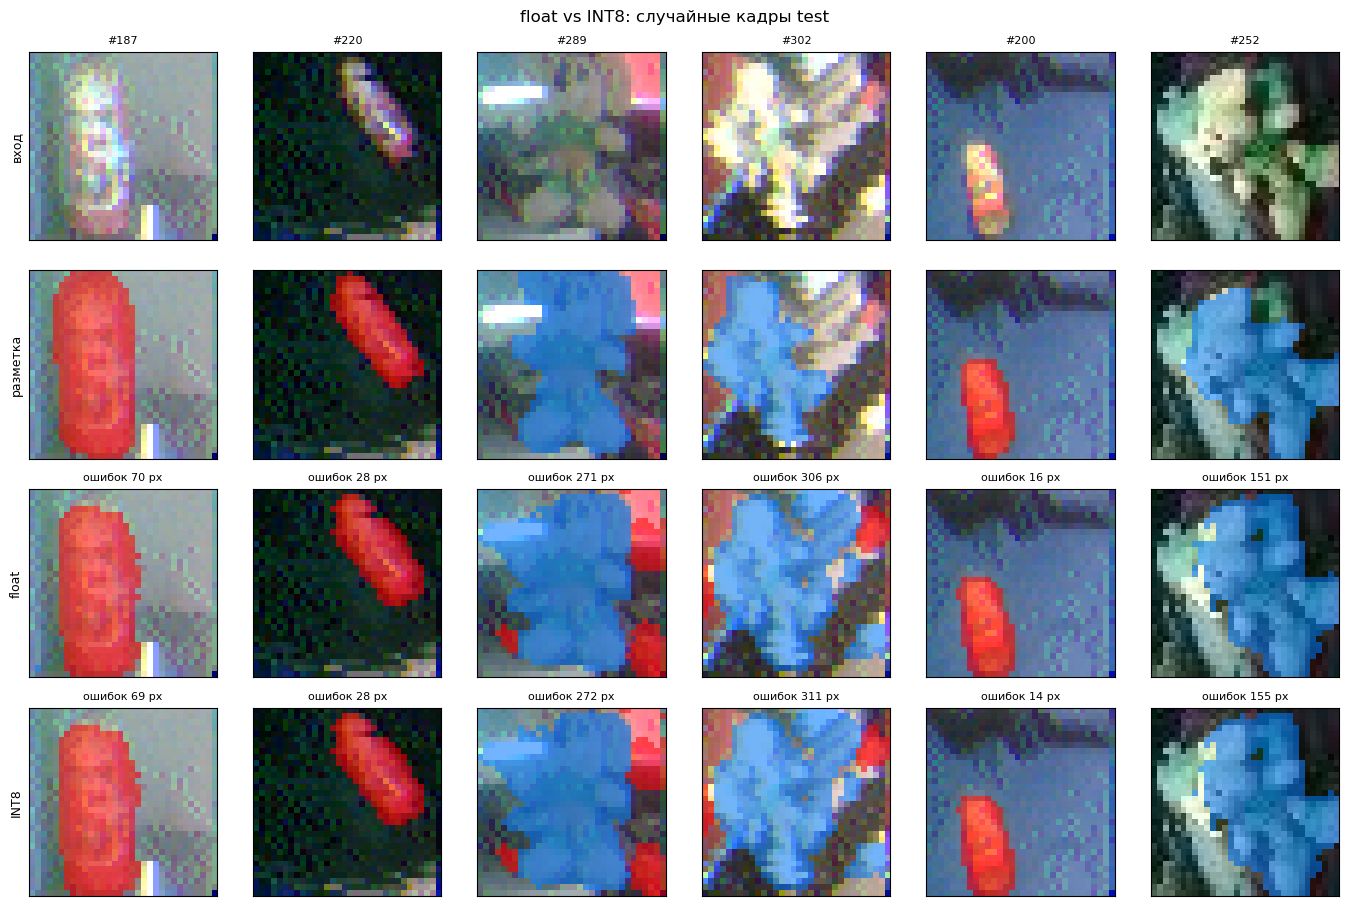

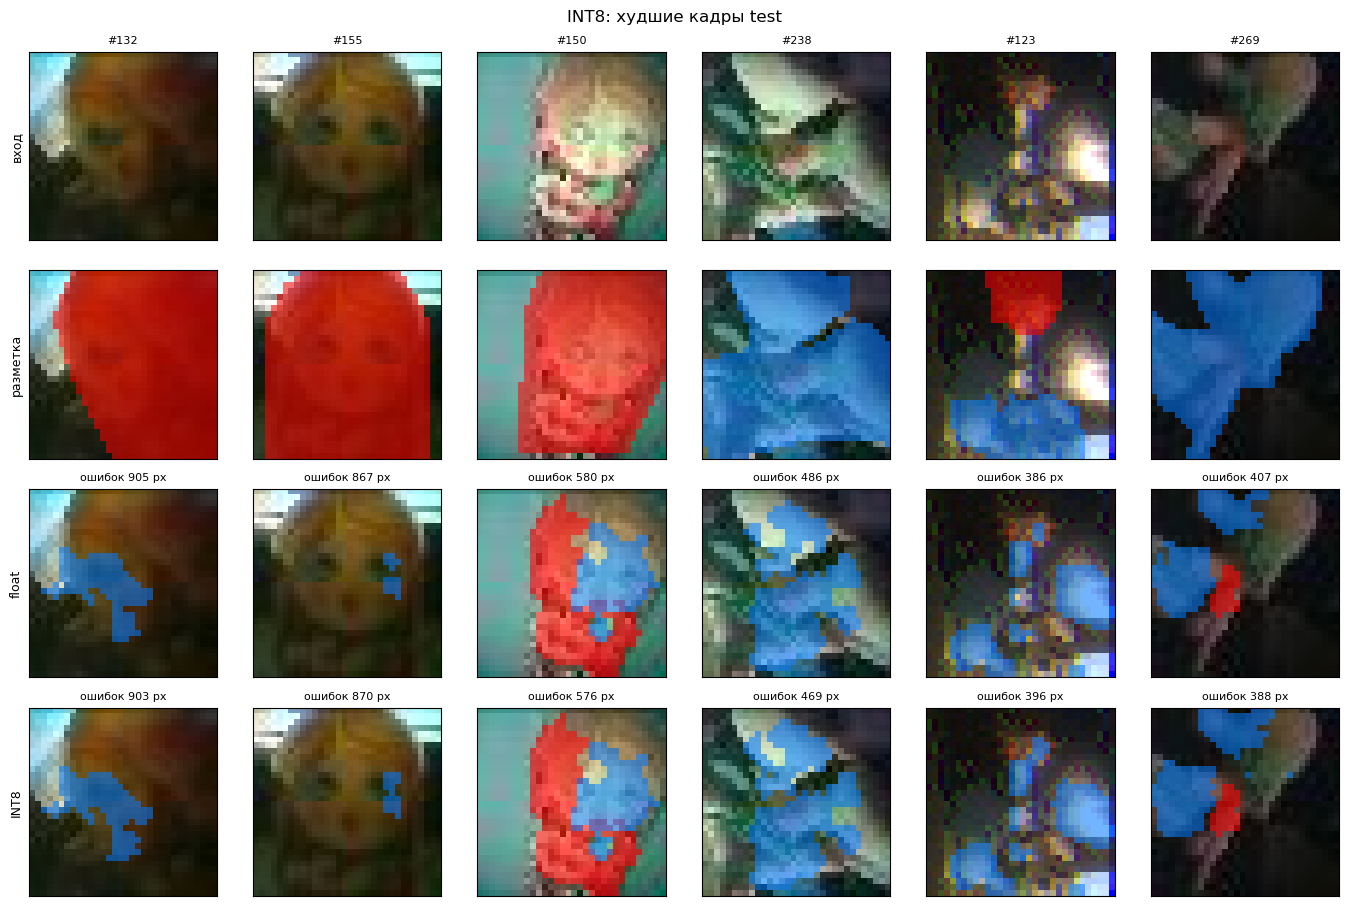

In [24]:
q_val, q_test = seg_q.predict_q(val_data["images"]), seg_q.predict_q(test_data["images"])
dq = lambda q: (q.astype(np.float32) - seg_q.out_zp) * seg_q.out_scale
for split, d, pf, q in (("val", val_data, val_prob, q_val), ("test", test_data, test_prob, q_test)):
    m_f = seg_metrics(pf, d["masks"], OP_THR); m_q = seg_metrics(np_sigmoid(dq(q)), d["masks"], OP_THR)
    mi = q_mask(q, QTHR); m_i = seg_metrics(mi.astype(np.float32), d["masks"], 0.5)
    print("[%-4s] float : %s" % (split, fmt_seg(m_f))); print("       INT8  : %s   Δ mIoU = %+.3f" % (fmt_seg(m_q), m_q["miou"] - m_f["miou"]))
    print("       INT8 q: %s   (целочисленные пороги, как на МК)" % fmt_seg(m_i))
    same = float((mi == (np_sigmoid(dq(q)) >= OP_THR)).mean()); print("       совпадение масок «целочисленные пороги» и «dequant+sigmoid»: %.4f %%" % (100 * same))
    print("       маски float vs INT8 различаются в %.3f %% пикселей" % (100 * float((mi != (pf >= OP_THR)).mean())))

f_logits = predict_logits_keras(trainer.model, val_data["images"]); err = np.abs(dq(q_val) - f_logits)
print("\nОшибка квантования логитов (val): mean %.4f, max %.3f (%.1f %% диапазона %.2f..%.2f)" % (err.mean(), err.max(), 100 * err.max() / max(f_logits.max() - f_logits.min(), 1e-9), f_logits.min(), f_logits.max()))

test_prob_q = np_sigmoid(dq(q_test))
_rnd = np.random.default_rng(7).choice(len(test_data["images"]), 6, replace=False)
show_pred_grid(test_data, {"float": test_prob, "INT8": test_prob_q}, _rnd, OP_THR, "float vs INT8: случайные кадры test")
show_pred_grid(test_data, {"float": test_prob, "INT8": test_prob_q}, worst_frames(test_data, test_prob_q, OP_THR, 6), OP_THR, "INT8: худшие кадры test")

# Шаг 11. Экспорт для Zephyr/TFLM
Модуль пакует квантованную модель и формирует файлы для проекта:
* `model.hpp` — модель в виде C-массива;
* `seg_config.h` — размеры, параметры квантования входа/выхода, **целочисленные пороги классов**, метки и цвета;
* `seg_postprocess.h/.c` — из int8-логитов делает битовую маску (бит `k` = класс `k`, классы могут перекрываться) и умеет наложить её на RGB565-кадр для дисплея;
* `seg_selftest.h` — два контрольных кадра (вход int8 и ожидаемая маска): позволяют быстро убедиться на плате, что препроцессинг, модель и постобработка работают так же, как в ноутбуке;
* фрагмент `MicroMutableOpResolver` и оценка арены.

In [25]:
# Конвертирует .tflite в заголовочный файл C++ (.hpp).
def tflite_to_hpp(blob, path, name="g_model"):
    hexes = ["0x%02x" % b for b in blob]
    lines = [", ".join(hexes[i:i + 16]) for i in range(0, len(hexes), 16)]
    txt = ("/* автогенерация TFL-Segmentation.ipynb; sha1=%s */\n#pragma once\nalignas(16) const unsigned char %s[] = {\n  " % (hashlib.sha1(blob).hexdigest()[:12], name)
           + ",\n  ".join(lines) + "\n};\nconst unsigned int %s_len = %d;\n" % (name, len(blob)))
    Path(path).write_text(txt)

# Конфигурационный заголовок для МК: размеры, квантование, целочисленные пороги, метки, цвета.
def write_seg_config(path, labels, colors, in_scale, in_zp, out_scale, out_zp, qthr, thr, in_hw=(IMG, IMG), out_hw=(IMG, IMG)):
    L_ = ["/* автогенерация TFL-Segmentation.ipynb — не править вручную */", "#ifndef SEG_CONFIG_H_", "#define SEG_CONFIG_H_", "", "#include <stdint.h>", "",
          "#define SEG_NUM_CLASSES %d" % len(labels), "#define SEG_INPUT_W %d" % in_hw[1], "#define SEG_INPUT_H %d" % in_hw[0],
          "#define SEG_INPUT_SCALE %.9gf" % float(in_scale), "#define SEG_INPUT_ZERO_POINT %d" % int(in_zp),
          "/* квантование входа: q = clamp(round(pix/255/SEG_INPUT_SCALE) + SEG_INPUT_ZERO_POINT, -128, 127) */", "",
          "#define SEG_OUT_W %d" % out_hw[1], "#define SEG_OUT_H %d" % out_hw[0],
          "/* параметры выходного тензора: на плате сверить с output(0)->params (пороги ниже посчитаны именно для них) */",
          "#define SEG_OUT_SCALE %.9gf" % float(out_scale), "#define SEG_OUT_ZERO_POINT %d" % int(out_zp), "",
          "/* пиксель принадлежит классу c, если int8-логит >= SEG_Q_THR[c] (128 = никогда, -128 = всегда).",
          "   Пороги вероятности: " + ", ".join("%s=%.2f" % (l, t) for l, t in zip(labels, thr)) + " */",
          "static const int SEG_Q_THR[SEG_NUM_CLASSES] = {" + ", ".join(str(int(q)) for q in qthr) + "};", "",
          "static const char *const SEG_LABELS[SEG_NUM_CLASSES] = {" + ", ".join('"%s"' % l for l in labels) + "};",
          "static const uint8_t SEG_COLORS[SEG_NUM_CLASSES][3] = {" + ", ".join("{%d, %d, %d}" % tuple(c) for c in colors) + "};",
          "#define SEG_OVERLAY_ALPHA 128      /* прозрачность наложения 0..256 */",
          "#define SEG_RGB565_BYTESWAP 0      /* 1, если дисплей ожидает RGB565 со сменой порядка байт */", "", "#endif /* SEG_CONFIG_H_ */", ""]
    Path(path).write_text("\n".join(L_))

# Контрольные кадры для самопроверки на плате: квантованный вход и ожидаемая битовая маска.
def write_selftest(path, qin, bits):
    N = len(qin); L_ = ["/* автогенерация TFL-Segmentation.ipynb — контрольные кадры для самопроверки */", "#ifndef SEG_SELFTEST_H_", "#define SEG_SELFTEST_H_", "", "#include <stdint.h>", "",
                        "#define SEG_SELFTEST_N %d" % N, "/* вход: int8 NHWC, как после квантования; маска: бит k = класс k */",
                        "static const int8_t SEG_SELFTEST_IN[SEG_SELFTEST_N][%d] = {" % qin[0].size]
    for a in qin: L_.append("  {" + ", ".join(str(int(v)) for v in a.ravel()) + "},")
    L_ += ["};", "static const uint8_t SEG_SELFTEST_MASK[SEG_SELFTEST_N][%d] = {" % bits[0].size]
    for b in bits: L_.append("  {" + ", ".join(str(int(v)) for v in b.ravel()) + "},")
    L_ += ["};", "", "#endif /* SEG_SELFTEST_H_ */", ""]
    Path(path).write_text("\n".join(L_))

# Битовая маска [N,H,W] uint8 из int8-логитов по целочисленным порогам (бит k = класс k) — зеркало seg_postprocess.c.
def q_to_bits(q, qthr):
    m = q_mask(q, qthr).astype(np.uint8); return sum((m[..., c] << c) for c in range(m.shape[-1])).astype(np.uint8)

In [26]:
SEG_POSTPROCESS_H = r"""/*
 * seg_postprocess.h — постобработка сегментации (UNet) для TFLM-int8 модели.
 * Без динамической памяти и без float: пороги заданы в целых числах в seg_config.h
 * (генерируется ноутбуком TFL-Segmentation.ipynb вместе с model.hpp).
 */
#ifndef SEG_POSTPROCESS_H_
#define SEG_POSTPROCESS_H_

#include <stdint.h>

#ifdef __cplusplus
extern "C" {
#endif

/*
 * logits    — int8-выход модели, NHWC [SEG_OUT_H][SEG_OUT_W][SEG_NUM_CLASSES] (output(0)->data.int8).
 * mask      — SEG_OUT_H*SEG_OUT_W байт; бит k байта = пиксель принадлежит классу k (классы могут перекрываться).
 * class_px  — необязательно (может быть NULL): число пикселей каждого класса [SEG_NUM_CLASSES].
 * Возвращает число пикселей, отнесённых хотя бы к одному классу.
 */
int seg_postprocess(const int8_t *logits, uint8_t *mask, int *class_px);

/*
 * Накладывает маску на RGB565-кадр SEG_OUT_W x SEG_OUT_H (цвета классов и прозрачность — в seg_config.h).
 */
void seg_overlay_rgb565(const uint8_t *mask, uint16_t *img565);

#ifdef __cplusplus
}
#endif

#endif /* SEG_POSTPROCESS_H_ */
"""

SEG_POSTPROCESS_C = r"""#include "seg_postprocess.h"
#include "seg_config.h"

int seg_postprocess(const int8_t *logits, uint8_t *mask, int *class_px)
{
	int total = 0;

	if (class_px) {
		for (int c = 0; c < SEG_NUM_CLASSES; c++) {
			class_px[c] = 0;
		}
	}
	for (int p = 0; p < SEG_OUT_H * SEG_OUT_W; p++) {
		uint8_t bits = 0;

		for (int c = 0; c < SEG_NUM_CLASSES; c++) {
			if ((int)logits[p * SEG_NUM_CLASSES + c] >= SEG_Q_THR[c]) {
				bits |= (uint8_t)(1u << c);
				if (class_px) {
					class_px[c]++;
				}
			}
		}
		mask[p] = bits;
		if (bits) {
			total++;
		}
	}
	return total;
}

static inline uint16_t swap16(uint16_t v)
{
	return (uint16_t)((v >> 8) | (v << 8));
}

/* Смешивание пикселя RGB565 с цветом rgb888; a = 0..256. */
static inline uint16_t blend565(uint16_t px, const uint8_t rgb[3], int a)
{
	int r = (px >> 11) & 0x1F, g = (px >> 5) & 0x3F, b = px & 0x1F;

	r = (r << 3) | (r >> 2);
	g = (g << 2) | (g >> 4);
	b = (b << 3) | (b >> 2);
	r = (r * (256 - a) + rgb[0] * a) >> 8;
	g = (g * (256 - a) + rgb[1] * a) >> 8;
	b = (b * (256 - a) + rgb[2] * a) >> 8;
	return (uint16_t)(((r >> 3) << 11) | ((g >> 2) << 5) | (b >> 3));
}

void seg_overlay_rgb565(const uint8_t *mask, uint16_t *img565)
{
	for (int p = 0; p < SEG_OUT_H * SEG_OUT_W; p++) {
		uint8_t bits = mask[p];

		if (!bits) {
			continue;
		}
		uint16_t px = img565[p];
#if SEG_RGB565_BYTESWAP
		px = swap16(px);
#endif
		for (int c = 0; c < SEG_NUM_CLASSES; c++) {
			if (bits & (1u << c)) {
				px = blend565(px, SEG_COLORS[c], SEG_OVERLAY_ALPHA);
			}
		}
#if SEG_RGB565_BYTESWAP
		px = swap16(px);
#endif
		img565[p] = px;
	}
}
"""

# Модель для переноса на микроконтроллер: пишем все файлы экспорта.
d_, ops = seg_q, interpreter_ops(blob)
tflite_to_hpp(blob, OUT_DIR / "model.hpp")
write_seg_config(OUT_DIR / "seg_config.h", FG, COLORS, d_.in_scale, d_.in_zp, d_.out_scale, d_.out_zp, QTHR, OP_THR)
(OUT_DIR / "seg_postprocess.h").write_text(SEG_POSTPROCESS_H); (OUT_DIR / "seg_postprocess.c").write_text(SEG_POSTPROCESS_C)
np.save(OUT_DIR / "op_thr.npy", OP_THR)

# Контрольные кадры: первый кадр теста с обоими классами (или с любым объектом) и первый фоновый кадр.
_m = test_data["masks"] > 0; _has = _m.reshape(len(_m), -1, NC).any(1)
_i_fg = next((i for i in range(len(_m)) if _has[i].all()), next((i for i in range(len(_m)) if _has[i].any()), 0))
_i_bg = next((i for i in range(len(_m)) if not _has[i].any()), 0)
_sel = [_i_fg, _i_bg]; _qin = np.stack([d_.quant_input(test_data["images"][i].astype(np.float32) / 255.0) for i in _sel])
_qout = np.stack([d_.run_q(test_data["images"][i].astype(np.float32) / 255.0) for i in _sel])
write_selftest(OUT_DIR / "seg_selftest.h", _qin, q_to_bits(_qout, QTHR))

peak, k_, opn = arena_lower_bound(blob)
print("\nЭкспорт: модель %.1f КБ | операции: %s" % (len(blob) / 1024, sorted(set(ops))))
print("Нижняя оценка арены (пик живых активаций): ~%.1f КБ, пик на операции #%d %s (цель ~64 КБ, допустимо до 150 КБ; реальное значение — arena_used_bytes() на плате)" % (peak / 1024, k_, opn))
print("\n// --- для tflm_wrapper.cpp ---\n" + resolver_snippet(ops))
print("\nФайлы в %s: model.hpp, seg_config.h, seg_postprocess.[ch], seg_selftest.h (кадры test #%s), unet_int8.tflite" % (OUT_DIR.resolve(), _sel))


Экспорт: модель 58.2 КБ | операции: ['CONCATENATION', 'CONV_2D', 'DEPTHWISE_CONV_2D', 'MAX_POOL_2D', 'RESIZE_NEAREST_NEIGHBOR']
Нижняя оценка арены (пик живых активаций): ~99.0 КБ, пик на операции #24 DEPTHWISE_CONV_2D (цель ~64 КБ, допустимо до 150 КБ; реальное значение — arena_used_bytes() на плате)

// --- для tflm_wrapper.cpp ---
static tflite::MicroMutableOpResolver<5> micro_op_resolver;
	micro_op_resolver.AddConcatenation();
	micro_op_resolver.AddConv2D();
	micro_op_resolver.AddDepthwiseConv2D();
	micro_op_resolver.AddMaxPool2D();
	micro_op_resolver.AddResizeNearestNeighbor();

Файлы в C:\Users\STEPANJUK\Desktop\TFL\TensorFlowLite\TFL_Segmentation\exportUBUNTU: model.hpp, seg_config.h, seg_postprocess.[ch], seg_selftest.h (кадры test #[100, 0]), unet_int8.tflite


# Шаг 12. Интеграция в Zephyr-проект
1. Положить `model.hpp`, `seg_config.h`, `seg_postprocess.[ch]` (и по желанию `seg_selftest.h`) в проект.
2. В `tflm_wrapper.cpp` заменить op-resolver на сгенерированный выше (`RESIZE_NEAREST_NEIGHBOR` и `CONCATENATION` уже поддерживаются TFLM).
3. `kTensorArenaSize` — начать с оценки арены из предыдущей ячейки с запасом (например, ×1.3), затем посмотреть `interpreter.arena_used_bytes()` и уменьшить.
4. Препроцессинг входа — тот же, что у классификатора и детектора: кадр 32×32, `q = clamp(round(pix/255/SEG_INPUT_SCALE) + SEG_INPUT_ZERO_POINT, -128, 127)` (обычно это `pix - 128`).
5. После `Invoke()`:
```c
TfLiteTensor *out = interpreter.output(0);
/* пороги в seg_config.h посчитаны для этих параметров выхода — на всякий случай сверить */
static uint8_t mask[SEG_OUT_H * SEG_OUT_W];
int px[SEG_NUM_CLASSES];
seg_postprocess(out->data.int8, mask, px);   /* бит k маски = класс k */
seg_overlay_rgb565(mask, frame565);          /* наложение на RGB565-кадр 32x32 для дисплея */
```
6. Самопроверка: прогнать `SEG_SELFTEST_IN[i]` через модель и сравнить итоговую маску с `SEG_SELFTEST_MASK[i]`. Допускается отличие на единицы пикселей из-за разницы референсных ядер; если маска сильно отличается — проблема в препроцессинге, op-resolver или расположении тензоров.

# Учебное пособие:

### TensorFlow:
##### ESP32-CAM 15: TensorFlow LITE классификация изображений
https://www.youtube.com/watch?v=ORJrzHiHIDc&t=660s

https://vkvideo.ru/video63898488_456239464?pl=63898488_-2

##### ESP32 + CatBoost: Decision Trees for Color Classification (GY-31-TCS230)
https://www.youtube.com/watch?v=CmU3OemU6gk

https://vkvideo.ru/video-229753773_456239017

##### ESP32 + KNN: Метод K-ближайших соседей для классификации цветов (GY-31-TCS230)
https://www.youtube.com/watch?v=0kSWgAhEtCI

https://www.youtube.com/watch?v=0kSWgAhEtCI

##### ESP32 + TensorFlow Lite: Линейная модель для классификации цветов (GY-31-TCS230)
https://www.youtube.com/watch?v=DyiEhkdACyw

https://vkvideo.ru/video-229753773_456239019

##### ESP32 + LD2410: Линейная модель для классификации движений (TensorFlow)
https://www.youtube.com/watch?v=ds3CPqLV-MI

https://www.youtube.com/watch?v=ds3CPqLV-MI

##### ESP32 + LD2410: Сверточная нейронная сеть для классификации движений (TensorFlow)
https://www.youtube.com/watch?v=kC0A1RCqdIc

https://vkvideo.ru/video-229753773_456239021

##### ESP32 + LD2410: Рекуррентная нейронная сеть для классификации движений (TensorFlow)
https://www.youtube.com/watch?v=UZd4lkwPL3Q&t=1s

https://vkvideo.ru/video-229753773_456239022

##### ESP32 + LD2410: Трансформер и механизм внимания для классификации движений (TensorFlow)
https://www.youtube.com/watch?v=cPqogs8ARUU

https://vkvideo.ru/video-229753773_456239023

##### ESP32: распознавание речи нейросетью (TensorFlow Lite)
https://www.youtube.com/watch?v=IH22K1WFqjU

https://vkvideo.ru/video-229753773_456239025



### Введение в машинное обучение:
##### Лекция. Введение в машинное обучение.
https://www.youtube.com/watch?v=LcvKd42DGQU

https://vkvideo.ru/video-155161349_456239164

##### Семинар. Введение в машинное обучение.
https://www.youtube.com/watch?v=YMtsgx8oB24

### Линейные модели:
##### Лекция 2.1: Линейная регрессия.
https://www.youtube.com/watch?v=khdaLtu9i-s

https://vkvideo.ru/video-155161349_456239169

##### Лекция 2.2: LogLoss.
https://www.youtube.com/watch?v=HV4Bm8UJwIs

https://vkvideo.ru/video-155161349_456239170

##### Лекция. Логистическая регрессия
https://www.youtube.com/watch?v=twdZBko9vH4

##### Лекция. Градиентный спуск в линейных алгоритмах
https://www.youtube.com/watch?v=N5_VAN1nhm8

https://vkvideo.ru/video-155161349_456239172

##### Лекция. Регуляризация в линейной регрессии
https://www.youtube.com/watch?v=L_o8v5A23XA

https://vkvideo.ru/video-155161349_456239173

##### Лекция 2.6: Нормализация.
https://www.youtube.com/watch?v=tOiwAyilk3I

https://vkvideo.ru/video-155161349_456239174

##### Семинар. Линейная и логистическая регрессия
https://www.youtube.com/watch?v=5VOp5xmBvds

https://vkvideo.ru/video-155161349_456239177

##### Семинар. Регуляризация в линейной регрессии
https://www.youtube.com/watch?v=56YdhX0xj3k

https://vkvideo.ru/video-155161349_456239176

### Выбор модели:
##### Метрики машинного обучения
https://www.youtube.com/watch?v=TaTGunOAIK4

https://vkvideo.ru/video-155161349_456239195

##### Лекция. Решающие деревья
https://www.youtube.com/watch?v=MJwAoWFTMWw

https://vkvideo.ru/video-155161349_456239192

##### Лекция. Композиции алгоритмов
https://www.youtube.com/watch?v=vqF8wrWjR5s

https://vkvideo.ru/video-155161349_456239193

##### Лекция. Градиентный бустинг
https://www.youtube.com/watch?v=JElfEE1OrSU

##### Семинар. Model Selection
https://www.youtube.com/watch?v=B03CrtpYDi4

### Основы PyTorch:
##### Введение в нейронные сети. Часть 1. История развития Deep Learning
https://www.youtube.com/watch?v=ZfXpX8tMg-w

https://vkvideo.ru/video-155161349_456239204

##### Введение в нейронные сети. Часть 2. Механизм обратного распространения ошибки
https://www.youtube.com/watch?v=-yiq1DRX9K0

https://vkvideo.ru/video-155161349_456239205

##### Введение в нейронные сети. Часть 3. Функции активации. Краткий обзор применений CNN и RNN
https://www.youtube.com/watch?v=3F7rydcAa0w

https://vkvideo.ru/video-155161349_456239207

##### Лекция. Полносвязная нейронная сеть
https://www.youtube.com/watch?v=O0nGKKFyYT4

https://vkvideo.ru/video-155161349_456239206

##### Семинар. Введение в библиотеку Pytorch
https://www.youtube.com/watch?v=DU3-mc8qFxA

##### Семинар. Нейронная сеть на Pytorch
https://www.youtube.com/watch?v=1aOp0pOvczg

### Полносвязные и свёрточные нейронные сети:
##### Лекция. История развития сверточных нейронных сетей
https://www.youtube.com/watch?v=Xq76hQHCkvQ

https://vkvideo.ru/video-155161349_456239213

##### Лекция. Сверточные нейронные сети
https://www.youtube.com/watch?v=HpKGv-kYurk

https://vkvideo.ru/video-155161349_456239214

##### Лекция. Пулинг. Операция пулинга
https://www.youtube.com/watch?v=IxLuPHtZBTY

##### Лекция. Задачи компьютерного зрения
https://www.youtube.com/watch?v=3IPRcBIsgNA

https://vkvideo.ru/video-155161349_456239216

##### Семинар. Свёртка. Пулинг
https://www.youtube.com/watch?v=6TMeFrRCJ_0

https://vkvideo.ru/video-155161349_456239217

##### Семинар. Модули в PyTorch
https://www.youtube.com/watch?v=0R65rYFZe6U

https://vkvideo.ru/video-155161349_456239218

##### Семинар. Свёрточные сети.
https://www.youtube.com/watch?v=xgVr9vISm8w

### Пакетная нормализация, исключение (dropout), оптимизаторы:
##### Лекция. Градиентная оптимизация в Deep Learning
https://www.youtube.com/watch?v=6CvpMOO-DB4

https://vkvideo.ru/video-155161349_456239227

##### Лекция. Регуляризация в Deep Learning
https://www.youtube.com/watch?v=x72-oUjv1ew

https://vkvideo.ru/video-155161349_456239228

##### Семинар. PyTorch. Batch Normalization и Dropout
https://www.youtube.com/watch?v=Y9a5EfqM7RM

##### Семинар. PyTorch. Оптимизаторы
https://www.youtube.com/watch?v=Yh1VoUhS5MY

https://vkvideo.ru/video-155161349_456239230

### Cвёрточные нейронные сети:
##### Лекция. Архитектуры CNN
https://www.youtube.com/watch?v=TcUPuKpIlhQ

https://vkvideo.ru/video-155161349_456239232

##### Лекция. Transfer Learning
https://www.youtube.com/watch?v=oLpREso27Zw

https://vkvideo.ru/video-155161349_456239233

##### Семинар. Transfer Learning в компьютерном зрении
https://www.youtube.com/watch?v=4AUxDH4doV0

### Семантическая сегментация:
##### Семантическая сегментация. Введение
https://www.youtube.com/watch?v=tIqndofykgc

https://vkvideo.ru/video-155161349_456239239

##### Семантическая сегментация. Трюки: Deconvolution, Dilated Convolution
https://www.youtube.com/watch?v=K73tZxH9nvE

https://vkvideo.ru/video-155161349_456239240

##### Семантическая сегментация. Архитектура UNet
https://www.youtube.com/watch?v=yEuIV5FsRMs

https://vkvideo.ru/video-155161349_456239241

### Детекция объектов:
##### Лекция. Нейронная детекция объектов. Классификация (повторение).
https://www.youtube.com/watch?v=8D01Xo9hWgg

https://vkvideo.ru/video-155161349_456239244

##### Лекция. Нейронная детекция объектов. Основы.
https://www.youtube.com/watch?v=Y4JvVOaZWsU

https://vkvideo.ru/video-155161349_456239245

##### Лекция. Нейронная детекция объектов. Двухстадийные нейросети.
https://www.youtube.com/watch?v=WrKl7GHWilA

https://vkvideo.ru/video-155161349_456239246

##### Лекция. Нейронная детекция объектов. Одностадийные нейросети.
https://www.youtube.com/watch?v=OPK63uqAQLs

https://vkvideo.ru/video-155161349_456239247

##### Лекция. Нейронная детекция объектов. Современные подходы и задачи.
https://www.youtube.com/watch?v=6WXUNNYysww

https://vkvideo.ru/video-155161349_456239249

##### Практика. Нейронная детекция объектов. Запуск SSD, TorchHub.
https://www.youtube.com/watch?v=JX6N74K84n0

##### Практика. Нейронная детекция объектов. Обучение SSD, mmdetection.
https://www.youtube.com/watch?v=gw_IXcbhOO0

https://vkvideo.ru/video-155161349_456239251

### Автоэнкодеры:
##### Лекция. Генеративные модели, автоэнкодеры
https://www.youtube.com/watch?v=6qVfC7P9dEc

https://vkvideo.ru/video-155161349_456239260

##### Семинар. Автоэнкодеры
https://vkvideo.ru/video-155161349_456239258

https://www.youtube.com/watch?v=FUXsks9SPOQ

##### Семинар. VAE
https://www.youtube.com/watch?v=mqPw5Lm810o

### Генеративные модели:
##### Лекция. Генеративные модели. Генеративно-состязательные сети
https://www.youtube.com/watch?v=An20DOEOctc

##### Семинар. Генеративные модели. Генеративно-состязательные сети
https://www.youtube.com/watch?v=Anocy4ey0vs